# Practical 5: Solutions to the Exercises

## Subset Selection and Shrinkage Methods for Regression

This notebook contains complete worked solutions to the five exercises at the end of Practical 5. Each exercise is
laid out in the same way:

1. **Task**: the exercise, restated so this notebook can be read on its own.
2. **Concept**: the idea behind the exercise, explained before any code.
3. **Code**: every line carries a comment saying what it does.
4. **Line by line**: a walk through the cell in order, explaining each line or small group of lines.
5. **Reading the output**: what the printed numbers and the plots mean.
6. **Answer**: a direct answer to each written question of the exercise.

**How to run it.** Use *Kernel → Restart & Run All*. The whole notebook takes about two minutes; most of the time
goes into the setup (which repeats the cross-validation of the practical) and the bootstraps of Exercises 2 and 5.

**Section S (setup)** re-creates every function, dataset, split and result of the practical that the exercises
need. It is copied from the practical, nothing in it is new, and it ends by printing a few numbers so you can check
that they agree with the practical exactly.

**The test set.** As in the practical, `X_test_raw` and `y_test` are used only to **compare** methods whose settings
are already fixed, never to choose anything. The only exercise that touches the test set is Exercise 5, step 4,
which asks for one more row in the comparison table of 7c.

**Contents**

- S. Setup: everything from the practical that the exercises use
- Exercise 1: Perfectly correlated predictors
- Exercise 2: The one-standard-error rule for $\lambda$
- Exercise 3: Choosing the subset size by cross-validation
- Exercise 4: The elastic net
- Exercise 5: Forward stepwise on the 55 features
- Summary of the answers

## S. Setup: everything from the practical that the exercises use

### S1. Imports and display settings

In [1]:
import numpy as np                                   # arrays and all the numerical work
import pandas as pd                                  # tables, so results print with readable labels
import matplotlib.pyplot as plt                      # every plot in this notebook
import itertools                                     # combinations(): every subset of a given size

from sklearn.datasets import load_diabetes           # the Diabetes dataset of the practical
from sklearn.preprocessing import StandardScaler, PolynomialFeatures   # rescaling, and products of features
from sklearn.pipeline import make_pipeline           # chain "standardise, then model" into one object
from sklearn.model_selection import train_test_split, KFold            # hold-out split and K-fold

# Library versions of methods we build ourselves. As in the practical, they are used ONLY to check our code,
# except in Part 7c, where the practical lets GridSearchCV choose lambda for the 55 features.
from sklearn.linear_model import LinearRegression, Ridge, Lasso  # OLS, ridge and lasso from the library
from sklearn.model_selection import GridSearchCV     # cross-validated search over a grid

%matplotlib inline

np.set_printoptions(precision=4, suppress=True)      # print arrays with 4 decimals, no scientific notation
pd.set_option("display.precision", 4)                # the same for DataFrames
pd.set_option("display.width", 150)                  # wide tables print on one line
plt.rcParams["figure.figsize"] = (6, 4)              # default plot size in inches
plt.rcParams["figure.dpi"] = 150                     # resolution of the figures

**Line by line**

- `numpy`, `pandas`, `matplotlib.pyplot` : the three standard imports of every practical.
- `itertools` : part of standard Python; `itertools.combinations` lists every subset of a given size, which
  `best_subset` needs (Exercise 3 runs it again inside every fold).
- `load_diabetes`, `StandardScaler`, `PolynomialFeatures`, `make_pipeline`, `train_test_split`, `KFold` : the
  data, the scaler, the product features of Part 7, the pipeline maker and the two splitters of the practical.
- `LinearRegression`, `Ridge`, `Lasso`, `GridSearchCV` : library versions, used for checks (Exercise 1 also uses
  `LinearRegression` to see how the library copes with a duplicated column) and, as in the practical, by
  `GridSearchCV` to choose $\lambda$ for the 55 features.
- What is **not** imported here: `SequentialFeatureSelector` and `statsmodels` were only needed for checks in the
  practical that the exercises do not repeat. The two extra tools the exercises ask for, `ElasticNet` (Exercise 4)
  and `time` (Exercise 5), are imported in the cell where they are first used.
- `np.set_printoptions`, `pd.set_option`, `plt.rcParams` : the display settings of the practical.

### S2. The functions written in the practical

Every function below is copied from the practical, with the same behaviour. The table says where each one was
explained in detail.

| function | what it does | practical section |
|-|-|-|
| `standardise` | rescale columns with the mean and std of another matrix | 1b |
| `ols_fit`, `predict`, `mse` | least squares by the normal equations; predictions; mean squared error | 2a |
| `rss` | the RSS of the OLS model on a chosen set of columns | 2c |
| `best_subset` | every subset of every size; keep the smallest RSS per size | 3a |
| `forward_stepwise` | greedily add the column that lowers RSS the most | 4a |
| `ridge_fit` | ridge regression in closed form | 5a |
| `soft_threshold`, `lasso_fit` | the soft-thresholding function and the lasso by coordinate descent | 5b, 5c |
| `ridge_path`, `lasso_path` | fits for a whole grid of $\lambda$ values | 6a |
| `cv_errors` | K-fold CV of a whole path, standardising inside each fold | 6b |
| `criteria` | AIC, BIC, $C_p$ and adjusted $R^2$ (defined in S4, after the numbers it needs) | 2d |

In [2]:
def standardise(X_fit, X_apply):
    '''Rescale the columns of X_apply using the mean and standard deviation of the columns of X_fit.'''
    mean = X_fit.mean(axis=0)                      # one mean per column, from X_fit only
    sd = X_fit.std(axis=0)                         # one standard deviation per column, from X_fit only
    return (X_apply - mean) / sd                   # broadcasting: every row is rescaled column by column


def ols_fit(Z, y):
    '''Ordinary least squares with an intercept, by the normal equations. returns (b0, b).'''
    A = np.column_stack([np.ones(len(y)), Z])      # a column of 1s in front, for the intercept
    w = np.linalg.solve(A.T @ A, A.T @ y)          # solve the normal equations (A^T A) w = A^T y
    return w[0], w[1:]                             # intercept, then the coefficients


def predict(b0, b, Z):
    '''Predictions of a linear model: b0 + Z b.'''
    return b0 + Z @ b


def mse(y_true, y_pred):
    '''Mean squared error.'''
    return np.mean((y_true - y_pred) ** 2)


def rss(Z, y, cols):
    '''Residual sum of squares of the OLS model that uses only the columns listed in cols.'''
    b0, b = ols_fit(Z[:, cols], y)                 # fit on the chosen columns only
    residuals = y - predict(b0, b, Z[:, cols])     # what the model misses on its own training rows
    return residuals @ residuals                   # the sum of the squared residuals


def best_subset(Z, y):
    '''Best-subset selection: for every size d, try every set of d columns, keep the smallest RSS.'''
    p = Z.shape[1]                                             # number of candidate columns
    best_cols, best_rss, all_sizes, all_rss = [], [], [], []  # four lists, filled below
    for d in range(p + 1):                                     # every size, 0 to p
        smallest, winner = np.inf, None                        # nothing tried yet for this size
        for cols in itertools.combinations(range(p), d):       # every set of d column numbers
            r = rss(Z, y, list(cols))                # RSS of this subset
            all_sizes.append(d)                      # record every model tried ...
            all_rss.append(r)                        # ... and its RSS
            if r < smallest:                                   # a new best model of this size
                smallest, winner = r, list(cols)     # remember it
        best_cols.append(winner)                     # the best model of size d
        best_rss.append(smallest)                    # and its RSS
    return best_cols, np.array(best_rss), np.array(all_sizes), np.array(all_rss)


def forward_stepwise(Z, y):
    '''Forward stepwise selection. returns path (path[d] = sorted columns of the size-d model) and n_fits.'''
    p = Z.shape[1]                                   # number of candidate columns
    chosen, path, n_fits = [], [[]], 1                         # the empty model counts as one fit
    while len(chosen) < p:                           # until every column is in
        candidates = [j for j in range(p) if j not in chosen]  # columns not yet in the model
        rss_each = [rss(Z, y, chosen + [j]) for j in candidates]   # try adding each one
        n_fits += len(candidates)                    # count the fits
        chosen = chosen + [candidates[int(np.argmin(rss_each))]]   # keep the one that lowers RSS most
        path.append(sorted(chosen))                  # the model of the next size
    return path, n_fits


def ridge_fit(Z, y, lam):
    '''Ridge regression in closed form. The intercept is not penalised. returns (b0, b).'''
    z_mean, y_mean = Z.mean(axis=0), y.mean()        # column means and target mean
    Zc, yc = Z - z_mean, y - y_mean                                   # centre the features and the target
    b = np.linalg.solve(Zc.T @ Zc + lam * np.eye(Z.shape[1]), Zc.T @ yc)   # (Z^T Z + lam I) b = Z^T y
    b0 = y_mean - z_mean @ b                                          # the intercept goes through the means
    return b0, b


def soft_threshold(z, lam):
    '''S(z, lam): move z towards 0 by lam, and stop at exactly 0 if |z| <= lam.'''
    return np.where(np.abs(z) > lam, z - np.sign(z) * lam, 0.0)


def lasso_fit(Z, y, lam, b_start=None, tol=1e-8, max_sweeps=100000):
    '''Lasso by coordinate descent, with scikit-learn's scaling: (1/2n) RSS + lam * sum |b_j|.'''
    n, p = Z.shape                                   # rows and columns
    z_mean, y_mean = Z.mean(axis=0), y.mean()        # column means and target mean
    Zc, yc = Z - z_mean, y - y_mean                 # centre, so the intercept can be found at the end
    col_sq = (Zc ** 2).mean(axis=0)                 # (1/n) x_j^T x_j for every column: 1 if standardised
    b = np.zeros(p) if b_start is None else b_start.copy()   # start from zeros, or from a warm start
    r = yc - Zc @ b                                 # the full residual of the current model
    for sweep in range(max_sweeps):
        biggest_change = 0.0                         # largest change in this sweep
        for j in range(p):                                      # one sweep over the coefficients
            rho = Zc[:, j] @ r / n + col_sq[j] * b[j]           # (1/n) x_j^T r^(j), using the full residual
            new_bj = soft_threshold(rho, lam) / col_sq[j]       # the one-coefficient lasso solution
            change = new_bj - b[j]                   # how much b_j moves
            if change != 0.0:
                r -= Zc[:, j] * change                          # keep the residual up to date
                b[j] = new_bj                        # store the new value
                biggest_change = max(biggest_change, abs(change))  # track the largest move
        if biggest_change < tol:                                # a whole sweep with (almost) no change: done
            break                                    # converged: leave the loop
    b0 = y_mean - z_mean @ b                         # the intercept goes through the means
    return b0, b


def ridge_path(Z, y, lams):
    '''Ridge fits for every lambda. returns (b0s, B): B[i] = the coefficients for lams[i].'''
    fits = [ridge_fit(Z, y, lam) for lam in lams]    # one closed-form fit per lambda
    return np.array([f[0] for f in fits]), np.array([f[1] for f in fits])


def lasso_path(Z, y, lams):
    '''Lasso fits for every lambda, from the largest lambda down, each warm-started from the previous answer.'''
    b0s, B = np.empty(len(lams)), np.empty((len(lams), Z.shape[1]))  # room for the results
    b = None                                             # the first (largest) lambda starts from zeros
    for i in np.argsort(lams)[::-1]:                     # positions of the lambdas, largest first
        b0s[i], B[i] = lasso_fit(Z, y, lams[i], b_start=b)  # warm-started fit
        b = B[i]                                         # warm start for the next, smaller lambda
    return b0s, B


def cv_errors(path_fn, X_raw, y, folds, lams):
    '''K-fold CV of a whole path of lambdas. returns an array (len(lams), K) of validation MSEs.'''
    errors = np.empty((len(lams), len(folds)))       # row = lambda, column = fold
    for f, (tr, va) in enumerate(folds):
        Z_tr = standardise(X_raw[tr], X_raw[tr])         # scale with the TRAINING part of this fold only
        Z_va = standardise(X_raw[tr], X_raw[va])     # validation part, training statistics
        b0s, B = path_fn(Z_tr, y[tr], lams)              # the whole path, fitted on the training part
        for i in range(len(lams)):
            errors[i, f] = mse(y[va], predict(b0s[i], B[i], Z_va))   # validation MSE of every lambda
    return errors


print("functions defined")

functions defined


**Line by line**

Each function was explained line by line in the practical (see the table above), and the comment on every line is a
reminder. Three details matter in the exercises:

- `ols_fit` solves the normal equations with `np.linalg.solve`. Exercise 1 shows what happens when $A^{\top}A$ is
  singular.
- `lasso_fit` updates one coefficient at a time, in the order of the columns, starting from zeros. Exercise 1 shows
  that this order can matter, and Exercise 4 changes a single line of it to get the elastic net.
- `best_subset`, `forward_stepwise` and `cv_errors` accept **any** matrix, so Exercises 3 and 5 can run them on a
  fold's training part or on the 55 features.

### S3. The data, the locked test set and the standardised features (Part 1)

In [3]:
diabetes = load_diabetes()                           # the Diabetes data of Part 0
X = diabetes.data                                    # (442, 10) feature matrix, one patient per row
y = diabetes.target                                  # (442,) disease progression after one year
feature_names = np.array(diabetes.feature_names)     # the 10 column names, as an array so we can index it

SEED_TEST = 2026                                     # the seed of the test split, fixed once in the practical
X_dev_raw, X_test_raw, y_dev, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED_TEST)  # 80 / 20
n_dev, p = X_dev_raw.shape                           # 353 development rows, 10 predictors

Z_dev = standardise(X_dev_raw, X_dev_raw)            # development rows, scaled with their own statistics
Z_test = standardise(X_dev_raw, X_test_raw)          # test rows, scaled with the DEVELOPMENT statistics

print("development:", Z_dev.shape, "   test:", Z_test.shape)
print("features   :", feature_names.tolist())

development: (353, 10)    test: (89, 10)
features   : ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


**Line by line**

- `load_diabetes()`, `.data`, `.target`, `feature_names` : the dataset of Part 0. Remember the column positions:
  `s1` is column **4** and `s2` is column **5**; Exercise 1 uses them.
- `train_test_split(..., random_state=SEED_TEST)` : exactly the split of 1a, so the development and test rows are the
  same patients as in the practical.
- `standardise(X_dev_raw, ...)` : the standardisation of 1b, always with the development statistics.

**Reading the output.** 353 development and 89 test patients, 10 features, as in the practical.

### S4. Results of the practical that the exercises compare with

This cell re-creates, with the practical's own code: the OLS fit (2a), the noise variance and the `criteria` function
(2d), best-subset selection and the sizes chosen by the four criteria (3b, 3c), the folds and the CV curves of ridge
and the lasso with the chosen $\lambda$ values (6b), and the 55-feature comparison of 7c. It then prints a few numbers
to compare with the practical.

In [4]:
# 2a: OLS on all ten standardised features
b0_ols, b_ols = ols_fit(Z_dev, y_dev)                # intercept and 10 coefficients

# 2c and 2d: total sum of squares, noise variance of the full model, and the four criteria
tss = np.sum((y_dev - y_dev.mean()) ** 2)            # RSS of the model that always predicts the mean
rss_full = rss(Z_dev, y_dev, list(range(p)))         # RSS of the full model with all p predictors
sigma2_hat = rss_full / (n_dev - p - 1)              # estimated noise variance, used by Cp


def criteria(rss_value, d, n=n_dev, tss=tss, sigma2=sigma2_hat):
    '''The four model-selection scores of an OLS model with d predictors plus an intercept.'''
    k = d + 1                                        # number of fitted parameters, intercept included
    return {"AIC": n * np.log(rss_value / n) + 2 * k,
            "BIC": n * np.log(rss_value / n) + np.log(n) * k,
            "Cp": rss_value / sigma2 - n + 2 * k,
            "adj R^2": 1 - (rss_value / (n - d - 1)) / (tss / (n - 1))}


# 3b and 3c: best subset, its table, and the size chosen by each criterion
bs_cols, bs_rss, all_sizes, all_rss = best_subset(Z_dev, y_dev)  # 1024 fits
bs_table = pd.DataFrame([{"d": d, "features": ", ".join(feature_names[bs_cols[d]]), "RSS": int(round(bs_rss[d])),
                          **criteria(bs_rss[d], d)} for d in range(p + 1)]).set_index("d")
best_d = {"AIC": bs_table["AIC"].idxmin(), "BIC": bs_table["BIC"].idxmin(),  # lower is better ...
          "Cp": bs_table["Cp"].idxmin(), "adj R^2": bs_table["adj R^2"].idxmax()}

# 6a and 6b: the lambda grids, the ten folds, the CV curves and the chosen lambdas
lams_ridge = np.logspace(-2, 5, 100)                 # 100 values from 0.01 to 100 000
lams_lasso = np.logspace(-2, 2, 100)                 # 100 values from 0.01 to 100
folds = list(KFold(n_splits=10, shuffle=True, random_state=0).split(X_dev_raw))   # ONE set of folds
K = len(folds)                                       # 10
ridge_cv = cv_errors(ridge_path, X_dev_raw, y_dev, folds, lams_ridge)   # shape (100, 10)
lasso_cv = cv_errors(lasso_path, X_dev_raw, y_dev, folds, lams_lasso)   # shape (100, 10)
lam_ridge = lams_ridge[int(np.argmin(ridge_cv.mean(axis=1)))]          # the CV-best ridge lambda
lam_lasso = lams_lasso[int(np.argmin(lasso_cv.mean(axis=1)))]          # the CV-best lasso lambda
N_BOOT = 200                                         # number of bootstrap samples in 7b and 7c

# 7c: the 55 features, lambda chosen by GridSearchCV on the same folds, the three final models
poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)  # pairwise products
X55_dev_raw = poly.fit_transform(X_dev_raw)          # (353, 55): the 10 features and the 45 products
X55_test_raw = poly.transform(X_test_raw)            # (89, 55): the same columns for the test patients
names55 = poly.get_feature_names_out(feature_names)  # readable names such as "bmi bp"
Z55_dev = standardise(X55_dev_raw, X55_dev_raw)      # standardised with development statistics
Z55_test = standardise(X55_dev_raw, X55_test_raw)    # test rows, development statistics
p55 = Z55_dev.shape[1]                               # 55
search55_ridge = GridSearchCV(make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": lams_ridge},
                              cv=folds, scoring="neg_mean_squared_error").fit(X55_dev_raw, y_dev)
search55_lasso = GridSearchCV(make_pipeline(StandardScaler(), Lasso(max_iter=100000)), {"lasso__alpha": lams_lasso},
                              cv=folds, scoring="neg_mean_squared_error").fit(X55_dev_raw, y_dev)
lam55_ridge = search55_ridge.best_params_["ridge__alpha"]  # the chosen ridge lambda
lam55_lasso = search55_lasso.best_params_["lasso__alpha"]  # the chosen lasso lambda
ols55_cv = cv_errors(ridge_path, X55_dev_raw, y_dev, folds, np.array([0.0])).mean()   # ridge at 0 is OLS
final55 = {"OLS": ols_fit(Z55_dev, y_dev),           # the three final models
           "ridge": ridge_fit(Z55_dev, y_dev, lam55_ridge),
           "lasso": lasso_fit(Z55_dev, y_dev, lam55_lasso)}
cv55 = {"OLS": ols55_cv, "ridge": -search55_ridge.best_score_, "lasso": -search55_lasso.best_score_}  # CV MSEs
setting55 = {"OLS": "all 55 features", "ridge": f"lambda = {lam55_ridge:.2f}", "lasso": f"lambda = {lam55_lasso:.3f}"}
rows = []                                            # one dictionary per row of the table
for name, (b0, b) in final55.items():
    squared_errors = (y_test - predict(b0, b, Z55_test)) ** 2        # the test set, used once per method
    rows.append({"method": name, "setting": setting55[name], "CV MSE": cv55[name],
                 "training MSE": mse(y_dev, predict(b0, b, Z55_dev)), "test MSE": squared_errors.mean(),
                 "standard error of test MSE": squared_errors.std() / np.sqrt(len(y_test)),
                 "zero coefficients": int(np.sum(b == 0)), "largest |coefficient|": np.abs(b).max()})
results55 = pd.DataFrame(rows).set_index("method")   # the table of 7c

print(f"2d  noise standard deviation sigma_hat : {np.sqrt(sigma2_hat):.2f}          (practical: 54.72)")
print(f"3c  sizes chosen by the criteria       : {best_d}   (practical: 6, 6, 6, 7)")
print(f"6b  CV-best lambda, ridge / lasso      : {lam_ridge:.4f} / {lam_lasso:.4f}   (practical: 29.1505 / 1.2619)")
print(f"7c  test MSE of OLS / ridge / lasso    : {results55['test MSE'].round(1).tolist()}"
      f"   (practical: 3470.3, 3020.0, 2764.9)")

2d  noise standard deviation sigma_hat : 54.72          (practical: 54.72)
3c  sizes chosen by the criteria       : {'AIC': 6, 'BIC': 6, 'Cp': 6, 'adj R^2': 7}   (practical: 6, 6, 6, 7)
6b  CV-best lambda, ridge / lasso      : 29.1505 / 1.2619   (practical: 29.1505 / 1.2619)
7c  test MSE of OLS / ridge / lasso    : [3470.3, 3020.0, 2764.9]   (practical: 3470.3, 3020.0, 2764.9)


**Line by line**

- The cell is the practical's own code for sections 2a, 2d, 3b, 3c, 6a, 6b and 7c, with the plots and the library
  checks removed. Each block starts with a comment naming the section.
- `def criteria(rss_value, d, n=n_dev, tss=tss, sigma2=sigma2_hat)` : the function is defined **after** `tss` and
  `sigma2_hat` exist, because Python fills in default values once, when the `def` line runs. Exercise 5 depends on
  this detail.
- `**criteria(bs_rss[d], d)` : unpacks the four scores into four more columns of the row (3b).
- `ridge_cv`, `lasso_cv` : the validation MSE of every $\lambda$ on every fold, the raw material of Exercise 2.
- `lam_ridge`, `lam_lasso` : the $\lambda$ with the smallest average CV error, as in 6b.
- The 7c block: product features, standardisation, $\lambda$ chosen by `GridSearchCV` on the same folds, the three
  final models fitted with our own functions, and the comparison table `results55`, to which Exercise 5 adds a row.

**Reading the output.** Every number agrees with the practical, so the exercises start from exactly the same place.

# Exercise 1: Perfectly correlated predictors

**Task.**

1. Build `Z_dup`: the development features plus an 11th column that is an exact copy of `s1`.
2. Try `ols_fit(Z_dup, y_dev)`. Do you get an error, or numbers that make no sense? Explain why, using the rank of
   $A^{\top}A$. Then try `LinearRegression().fit(Z_dup, y_dev)`. How do the two `s1` coefficients compare?
3. Fit `ridge_fit(Z_dup, y_dev, 10)`. Compare the two copies' coefficients with each other, and with the `s1`
   coefficient of `ridge_fit(Z_dev, y_dev, 10)`. What does ridge do with two identical columns?
4. Fit `lasso_fit(Z_dup, y_dev, 1.0)`. How is the weight split between the two copies? Move the copy to the front
   and fit again. What changes? What does this tell you about interpreting which of two correlated features the lasso
   keeps?

**Concept.** If column 11 is an exact copy of column 5 (`s1`), then any model can move weight freely between them:

$$\beta_{s1}\,x_{s1} + \beta_{\text{copy}}\,x_{\text{copy}} = (\beta_{s1} + \beta_{\text{copy}})\,x_{s1}.$$

Only the **sum** $\gamma = \beta_{s1} + \beta_{\text{copy}}$ affects the predictions and therefore the RSS. Every
method has to decide how to split $\gamma$ between the two copies, and the data cannot help it decide. What each
method does then depends only on its **penalty**:

| method | penalty on the two copies | consequence |
|-|-|-|
| OLS | none | every split gives the same RSS: infinitely many solutions |
| ridge | $\lambda(\beta_{s1}^2 + \beta_{\text{copy}}^2)$ | smallest when the split is equal: one unique solution, with equal halves |
| lasso | $\lambda(\lvert\beta_{s1}\rvert + \lvert\beta_{\text{copy}}\rvert)$ | equal to $\lambda\lvert\gamma\rvert$ for **every** split with the same sign: infinitely many solutions again |

The four steps below check each line of this table.

## 1.1 A duplicated column

In [5]:
Z_dup = np.column_stack([Z_dev, Z_dev[:, 4]])        # the 10 features, plus an 11th column: a copy of s1 (column 4)
names_dup = np.append(feature_names, "s1 copy")      # names for the 11 columns, for printing

print("shape of Z_dup               :", Z_dup.shape)
print("column 11 identical to s1    :", np.array_equal(Z_dup[:, 10], Z_dup[:, 4]))
print("correlation of the two copies:", np.corrcoef(Z_dup[:, 4], Z_dup[:, 10])[0, 1])

shape of Z_dup               : (353, 11)
column 11 identical to s1    : True
correlation of the two copies: 1.0


**Line by line**

- `Z_dev[:, 4]` : all rows of column 4, which is `s1` (columns are numbered from 0: age, sex, bmi, bp, s1, ...).
- `np.column_stack([Z_dev, Z_dev[:, 4]])` : glues the copy to the right of the 10 columns, giving 11 columns. The
  copy becomes column **10** of `Z_dup`.
- `np.append(feature_names, "s1 copy")` : a new array of 11 names, so printed coefficients can be labelled.
- `np.array_equal(...)` : `True` only if the two columns are equal in every entry.
- `np.corrcoef(a, b)[0, 1]` : the correlation of the two columns, the off-diagonal entry of the $2 \times 2$
  correlation matrix.

**Reading the output.** 353 rows and 11 columns; the last column is identical to `s1`, so their correlation is exactly
1: the most extreme case of correlated predictors.

## 1.2 OLS with a duplicated column

In [6]:
A_dup = np.column_stack([np.ones(n_dev), Z_dup])     # the matrix A of the normal equations: intercept + 11 columns
AtA = A_dup.T @ A_dup                                # the 12 x 12 matrix A^T A
print("shape of A^T A                 :", AtA.shape)
print("rank of A^T A                  :", np.linalg.matrix_rank(AtA))
print(f"smallest eigenvalue of A^T A   : {np.linalg.eigvalsh(AtA)[0]:.2e}   (largest {np.linalg.eigvalsh(AtA)[-1]:.1f})")
print(f"condition number of A^T A      : {np.linalg.cond(AtA):.2e}")

# our own OLS on the duplicated columns
try:
    b0_dup, b_dup = ols_fit(Z_dup, y_dev)            # may fail, or may return arbitrary numbers
    print("\nols_fit returned an answer (no error was raised):")
    print(f"   s1 coefficient {b_dup[4]:.4f},  copy coefficient {b_dup[10]:.4f},  their sum {b_dup[4] + b_dup[10]:.4f}")
    print(f"   training MSE {mse(y_dev, predict(b0_dup, b_dup, Z_dup)):.4f}"
          f"   (OLS on the 10 original features: {mse(y_dev, predict(b0_ols, b_ols, Z_dev)):.4f})")
except np.linalg.LinAlgError as error:               # the other possible outcome
    print("\nols_fit raised an error:", error)

# the library's OLS on the same columns
lib_dup = LinearRegression().fit(Z_dup, y_dev)       # the library on the 11 columns
print("\nLinearRegression:")
print(f"   s1 coefficient {lib_dup.coef_[4]:.4f},  copy coefficient {lib_dup.coef_[10]:.4f},"
      f"  their sum {lib_dup.coef_[4] + lib_dup.coef_[10]:.4f}")
print(f"   OLS s1 coefficient on the 10 original features: {b_ols[4]:.4f}")
print("   other 9 coefficients identical to OLS :", np.allclose(np.delete(lib_dup.coef_, [4, 10]), np.delete(b_ols, 4)))
print("   predictions identical to OLS          :", np.allclose(lib_dup.predict(Z_dup), predict(b0_ols, b_ols, Z_dev)))

shape of A^T A                 : (12, 12)
rank of A^T A                  : 11
smallest eigenvalue of A^T A   : -2.16e-13   (largest 1604.3)
condition number of A^T A      : 7.66e+15

ols_fit returned an answer (no error was raised):
   s1 coefficient 10.5157,  copy coefficient -50.9782,  their sum -40.4625
   training MSE 2900.9930   (OLS on the 10 original features: 2900.9930)

LinearRegression:
   s1 coefficient -20.2312,  copy coefficient -20.2312,  their sum -40.4625
   OLS s1 coefficient on the 10 original features: -40.4625
   other 9 coefficients identical to OLS : True
   predictions identical to OLS          : True


**Line by line**

- `A_dup = np.column_stack([np.ones(n_dev), Z_dup])` : the same matrix that `ols_fit` builds inside: a column of ones
  for the intercept, then the 11 feature columns, so 12 columns in all.
- `A_dup.T @ A_dup` : the $12 \times 12$ matrix of the normal equations $A^{\top}A\,w = A^{\top}y$.
- `np.linalg.matrix_rank(AtA)` : the number of linearly independent columns. A $12 \times 12$ matrix can be inverted
  only if its rank is 12.
- `np.linalg.eigvalsh(AtA)` : the eigenvalues of the symmetric matrix, smallest first. `[0]` is the smallest and
  `[-1]` the largest. The format `:.2e` prints a number in scientific notation with two decimals.
- `np.linalg.cond(AtA)` : the **condition number**, the largest eigenvalue divided by the smallest. Roughly, it says
  by how much rounding errors can be magnified when solving the system; around $10^{16}$ means "every digit of a
  double-precision number may be lost".
- `try: ... except np.linalg.LinAlgError as error:` : Python runs the indented lines under `try`; if one of them raises
  the error named after `except`, Python jumps to the `except` block instead of stopping the notebook. We write it
  this way because, as explained below, `ols_fit` can either fail or return numbers, depending on the computer.
- `np.delete(lib_dup.coef_, [4, 10])` : the coefficients without positions 4 and 10, to compare the other nine with
  OLS on the original features (where `np.delete(b_ols, 4)` removes `s1`).
- `lib_dup.predict(Z_dup)` : the library model's predictions, compared with those of our OLS on the 10 original
  columns.

**Reading the output.**

- $A^{\top}A$ has **rank 11, not 12**. Its smallest eigenvalue is zero up to rounding: it even comes out slightly
  **negative** ($-2 \times 10^{-13}$), which is impossible for $A^{\top}A$ in exact arithmetic, against a largest
  eigenvalue of about 1600. Its condition number is about $8 \times 10^{15}$.
- **Our `ols_fit`.** On the computer that produced this notebook, `np.linalg.solve` did **not** raise an error. It
  returned $+10.52$ for `s1` and $-50.98$ for the copy: numbers that make no sense on their own (higher cholesterol
  is now "good" in one column and "very bad" in the other). Yet their **sum** is $-40.46$, exactly the OLS `s1`
  coefficient of Part 2, and the training MSE is identical to OLS. On a different computer, or with a different
  version of NumPy, the same line can instead stop with `LinAlgError: Singular matrix`, or return a different pair
  of numbers with the same sum. All three outcomes have the same cause.
- **`LinearRegression`** returns an answer, and it is a sensible one: both copies get **$-20.23$, exactly half** of
  the OLS `s1` coefficient each. The other nine coefficients and all the predictions are identical to OLS on the 10
  original features.

**Answer.** The copy makes column 12 of $A$ equal to column 6 (the `s1` column; column 1 is the intercept), so $A$
has only 11 independent columns and $A^{\top}A$ has rank 11. A $12 \times 12$ matrix of rank 11 is **singular**: it
has an eigenvalue of 0 and no inverse, and the normal equations have **infinitely many** solutions, one for every way
of splitting $-40.46$ between the two copies, all with exactly the same RSS. `np.linalg.solve` assumes a unique
solution. In exact arithmetic it would have to divide by zero. In floating-point arithmetic the zero becomes a tiny
rounding error, so it either detects the problem and raises `LinAlgError`, or divides by that tiny number and returns
one essentially arbitrary split, as happened here. `LinearRegression` does not use the normal equations. It uses a
least-squares solver (`scipy.linalg.lstsq`, based on the singular value decomposition) that, when there are many
solutions, returns the one with the **smallest length** $\sum_j \beta_j^2$. For a fixed sum $\gamma$, the split with
the smallest $\beta_{s1}^2 + \beta_{\text{copy}}^2$ is the equal one, $\gamma/2$ each. So the library gives a sensible
answer, but only because it quietly makes a choice that the data cannot make.

## 1.3 Ridge with a duplicated column

In [7]:
lam = 10                                             # the lambda of the exercise
b0_rdup, b_rdup = ridge_fit(Z_dup, y_dev, lam)       # ridge on the 11 columns
b0_r10, b_r10 = ridge_fit(Z_dev, y_dev, lam)         # ridge on the 10 original columns

print(f"ridge on Z_dup : s1 {b_rdup[4]:.4f},  copy {b_rdup[10]:.4f},  sum {b_rdup[4] + b_rdup[10]:.4f}")
print(f"ridge on Z_dev : s1 {b_r10[4]:.4f}")
print("the two copies are equal:", np.isclose(b_rdup[4], b_rdup[10]))

# check: ridge on the 10 original columns, but with HALF the penalty on s1 only
Zc, yc = Z_dev - Z_dev.mean(axis=0), y_dev - y_dev.mean()   # centred, as inside ridge_fit
penalty = np.full(p, float(lam))                     # lambda for every coefficient ...
penalty[4] = lam / 2                                 # ... except s1, which gets lambda / 2
b_half = np.linalg.solve(Zc.T @ Zc + np.diag(penalty), Zc.T @ yc)  # ridge, one penalty per coefficient
print(f"\nridge on Z_dev with penalty lambda/2 on s1 only: s1 {b_half[4]:.4f}"
      f"   (equal to the sum of the two copies: {np.isclose(b_half[4], b_rdup[4] + b_rdup[10])})")
print("and the other nine coefficients agree too     :", np.allclose(np.delete(b_half, 4), np.delete(b_rdup, [4, 10])))

ridge on Z_dup : s1 -6.7928,  copy -6.7928,  sum -13.5856
ridge on Z_dev : s1 -10.8716
the two copies are equal: True

ridge on Z_dev with penalty lambda/2 on s1 only: s1 -13.5856   (equal to the sum of the two copies: True)
and the other nine coefficients agree too     : True


**Line by line**

- `ridge_fit(Z_dup, y_dev, lam)` : works without any problem. Ridge solves $(Z^{\top}Z + \lambda I)\,b = Z^{\top}y$, and
  adding $\lambda = 10$ to the diagonal lifts every eigenvalue by 10, so the matrix is no longer singular (5a).
- `np.isclose(b_rdup[4], b_rdup[10])` : checks that the two copies received the same coefficient.
- The check block builds ridge "by hand" on the 10 original columns with a **different penalty for each
  coefficient**:
  - `np.full(p, float(lam))` : an array of ten copies of $\lambda$;
  - `penalty[4] = lam / 2` : half the penalty for `s1`;
  - `np.diag(penalty)` : a diagonal matrix with these ten numbers, used in place of $\lambda I$.
- `np.delete(b_half, 4)` and `np.delete(b_rdup, [4, 10])` : the other nine coefficients of the two fits.

**Reading the output.**

- The two copies get **exactly the same coefficient**, $-6.79$ each, so their combined effect is $-13.59$.
- Ridge on the original 10 columns gives `s1` a coefficient of $-10.87$. So duplicating `s1` did not simply split the
  old coefficient in two: the **total** effect of `s1` became larger in size ($-13.59$ instead of $-10.87$).
- The check explains why: ridge on `Z_dup` is identical to ridge on `Z_dev` with **half the penalty** on `s1`.

**Answer.** With two identical columns, ridge has one unique answer and it **splits the weight equally** between the
copies. The reason is in the penalty. For a fixed total $\gamma$, the predictions and the RSS are the same for every
split, but $\beta_{s1}^2 + \beta_{\text{copy}}^2$ is smallest when $\beta_{s1} = \beta_{\text{copy}} = \gamma/2$. With
the equal split the penalty is $\lambda(\gamma^2/4 + \gamma^2/4) = \frac{\lambda}{2}\gamma^2$: duplicating a feature
halves the penalty on its total effect, which is why the total is shrunk less ($-13.59$) than in the model without the
copy ($-10.87$). This is the same **weight sharing** that 5a showed for the correlated pair `s1` and `s2`, taken to
its extreme.

## 1.4 The lasso with a duplicated column, and the order of the columns

In [8]:
def lasso_objective(Z, y, b0, b, lam):
    '''The lasso objective in scikit-learn's scaling: (1/2n) RSS + lam * sum |b_j|.'''
    return np.sum((y - b0 - Z @ b) ** 2) / (2 * len(y)) + lam * np.sum(np.abs(b))


lam = 1.0                                            # the lambda of the exercise
Z_front = np.column_stack([Z_dev[:, 4], Z_dev])      # the copy of s1 FIRST, then the 10 features (s1 is now column 5)

b0_back, b_back = lasso_fit(Z_dup, y_dev, lam)       # copy at the back (column 10), s1 at column 4
b0_front, b_front = lasso_fit(Z_front, y_dev, lam)   # copy at the front (column 0), s1 at column 5
b0_one, b_one = lasso_fit(Z_dev, y_dev, lam)         # no copy at all
lib_back = Lasso(alpha=lam, tol=1e-10, max_iter=100000).fit(Z_dup, y_dev)     # the library, copy at the back
lib_front = Lasso(alpha=lam, tol=1e-10, max_iter=100000).fit(Z_front, y_dev)  # the library, copy at the front

display(pd.DataFrame({                               # show the comparison table
    "coefficient of s1": [b_back[4], b_front[5], b_one[4]],
    "coefficient of the copy": [b_back[10], b_front[0], np.nan],
    "sum of the two": [b_back[4] + b_back[10], b_front[5] + b_front[0], b_one[4]],
    "lasso objective": [lasso_objective(Z_dup, y_dev, b0_back, b_back, lam),
                        lasso_objective(Z_front, y_dev, b0_front, b_front, lam),
                        lasso_objective(Z_dev, y_dev, b0_one, b_one, lam)],
    "same as sklearn Lasso": [np.allclose(b_back, lib_back.coef_, atol=1e-6),
                              np.allclose(b_front, lib_front.coef_, atol=1e-6), np.nan],
}, index=["copy at the back (Z_dup)", "copy at the front (Z_front)", "no copy (Z_dev)"]))

# the objective for other ways of splitting the same total between the two copies
total = b_back[4] + b_back[10]                       # the combined effect of s1, fixed
rows = []                                            # one dictionary per row of the table
for share in [0.0, 0.3, 0.5, 0.7, 1.0, 1.2]:         # fraction of the total given to s1
    b_try = b_back.copy()                            # start from the fitted coefficients
    b_try[4], b_try[10] = share * total, (1 - share) * total  # split the total
    rows.append({"share given to s1": share, "s1": b_try[4], "copy": b_try[10],
                 "lasso objective": lasso_objective(Z_dup, y_dev, b0_back, b_try, lam)})
pd.DataFrame(rows).set_index("share given to s1")    # display the table

,coefficient of s1,coefficient of the copy,sum of the two,lasso objective,same as sklearn Lasso
copy at the back (Z_dup),-0.0269,-7.4696,-7.4965,1557.8948,True
copy at the front (Z_front),-2.0731,-5.4235,-7.4965,1557.8948,True
no copy (Z_dev),-7.4965,NaN,-7.4965,1557.8948,NaN


,s1,copy,lasso objective
share given to s1,,,
0.0,-0.0000,-7.4965,1557.8948
0.3,-2.2490,-5.2476,1557.8948
0.5,-3.7483,-3.7483,1557.8948
0.7,-5.2476,-2.2490,1557.8948
1.0,-7.4965,-0.0000,1557.8948
1.2,-8.9958,1.4993,1560.8934


**Line by line**

- `lasso_objective(...)` : the quantity the lasso minimises, $\frac{1}{2n}\text{RSS} + \lambda\sum_j\lvert\beta_j\rvert$,
  so that different answers can be compared by their score.
- `np.column_stack([Z_dev[:, 4], Z_dev])` : the copy is now column 0 and the original `s1` has moved to column 5.
  Nothing about the data has changed, only the order of the columns.
- Three fits of our `lasso_fit`, and two of the library `Lasso` with the same tight tolerance as in 5c.
- In the first table the coefficients are read from the right positions: `b_back[4]` and `b_back[10]` for `Z_dup`,
  `b_front[5]` and `b_front[0]` for `Z_front`, `b_one[4]` for the model without a copy.
- `np.nan` : "not a number", used where a column does not apply (there is no copy in `Z_dev`).
- The loop takes the solution for `Z_dup`, keeps every other coefficient fixed, and redistributes the same total
  between `s1` and the copy: `share` of it to `s1` and the rest to the copy. A share of 1.2 gives `s1` more than the
  total, so the copy gets a coefficient of the **opposite** sign.

**Reading the output.**

- **Copy at the back:** `s1` gets $-0.03$ and the copy $-7.47$. **Copy at the front:** the copy gets $-5.42$ and `s1`
  gets $-2.07$. The split changes completely when only the order of the columns changes.
- The **sum** is $-7.497$ in both cases, exactly the `s1` coefficient of the lasso **without** a copy. The lasso
  objective is the same number (1557.89) for all three.
- `sklearn.Lasso` gives exactly the same uneven splits as our function, in both orders: it runs the same coordinate
  descent and updates the columns in the same order.
- The second table shows why: every split with both coefficients of the same sign (shares 0, 0.3, 0.5, 0.7 and 1)
  gives **the same objective**. Only the split with opposite signs (share 1.2) is worse.

**Answer.** With an exact copy, the lasso does **not** have a unique solution. For a fixed total $\gamma$, the RSS is
the same for every split, and $\lvert\beta_{s1}\rvert + \lvert\beta_{\text{copy}}\rvert = \lvert\gamma\rvert$ for every
split in which both have the same sign, so the penalty is the same too. There is a whole line of equally good answers,
and which point of it coordinate descent stops at depends on incidental details: the order in which the columns are
updated, the starting point, the tolerance. Moving the copy to the front changed the split from almost everything on
the copy (less than 1% on `s1`) to 28% on `s1` and 72% on the copy, while the total, the predictions and the
objective stayed exactly the same.

The lesson for interpretation: when two features are (nearly) interchangeable, **which one the lasso keeps tells you
almost nothing about which one matters**. With real data the pair is not identical, so one split is slightly better
than the others, but the choice is decided by small accidents of the sample. This is what 7b showed for `s1` and `s2`:
the lasso set `s2` to zero in 80% of the bootstrap samples, but not in all of them. A zero coefficient means "this
feature adds little once the others are in", not "this feature is unrelated to the target". (Exercise 4 shows how
the elastic net removes this ambiguity.)

# Exercise 2: The one-standard-error rule for $\lambda$

**Task.**

1. For ridge and for the lasso, find the **largest** $\lambda$ whose CV error is at most *(best CV error + its
   standard error)*, using `ridge_cv`, `lasso_cv`, `lams_ridge` and `lams_lasso`.
2. Redraw the two CV plots of 6b with this second $\lambda$ marked.
3. How many features does the lasso keep at the one-standard-error $\lambda$? Which ones?
4. Repeat the bootstrap of 7b for the lasso at this $\lambda$. Is it more or less stable than at the CV-best
   $\lambda$? Why might a simpler model be preferable when the CV errors cannot be told apart?

**Concept.** A CV error is an average of $K = 10$ fold errors, so it comes with a standard error,
$\text{SE} = \text{std over folds} / \sqrt{K}$. In 6b the curves were flat near the minimum: many values of
$\lambda$ had CV errors within one SE of the best. Those values cannot be told apart with the data we have. The
**one-standard-error rule** (Practical 4, Exercise 5) picks, among them, the **simplest** model. For ridge and the
lasso, "simplest" means the **most strongly penalised**, so the rule takes the **largest** $\lambda$ whose CV error is
at most $\text{CV}_{\text{best}} + \text{SE}_{\text{best}}$.

## 2.1 and 2.2 The one-standard-error $\lambda$, and the two CV plots

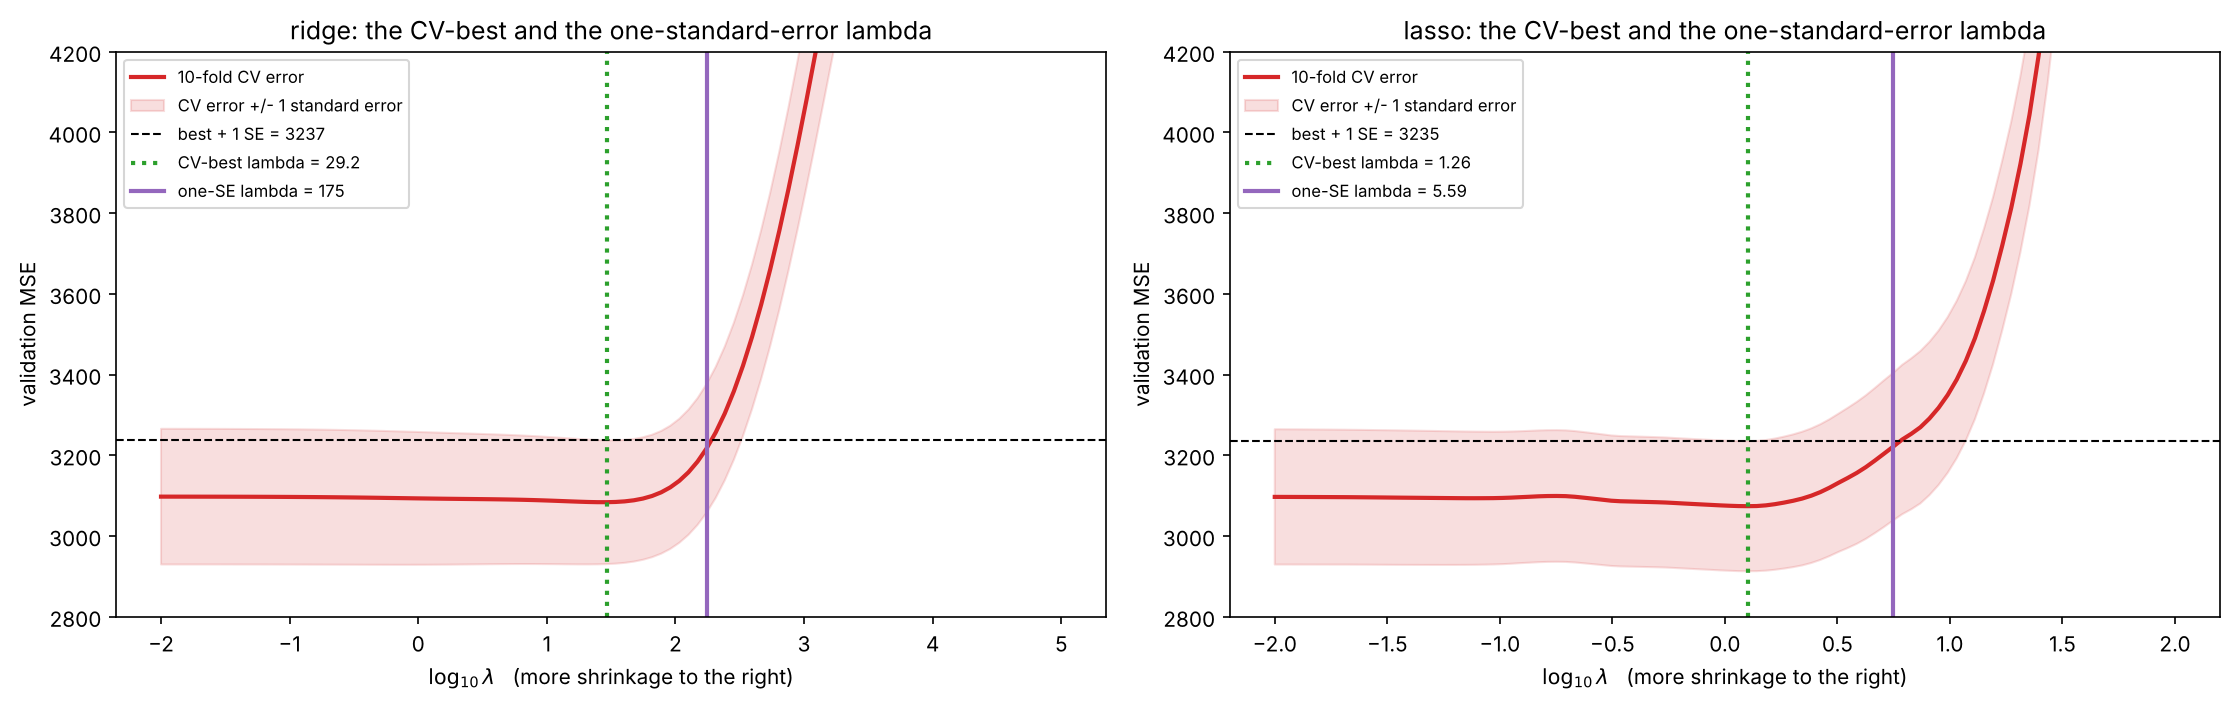

,ridge,lasso
CV-best lambda,29.1505,1.2619
CV error at best,3083.6888,3073.8238
SE at best,153.3947,161.2239
threshold,3237.0835,3235.0476
one-SE lambda,174.7528,5.5908
CV error at one-SE lambda,3216.9192,3221.1476
lambdas under the threshold,0.01 to 175,0.01 to 5.59


In [9]:
one_se = {}                                          # results for ridge and for the lasso
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))    # two panels, as in 6b
for ax, name, lams, errors in [(axes[0], "ridge", lams_ridge, ridge_cv), (axes[1], "lasso", lams_lasso, lasso_cv)]:
    mean = errors.mean(axis=1)                       # CV error of every lambda (average over the 10 folds)
    se = errors.std(axis=1) / np.sqrt(K)             # its standard error
    i_best = int(np.argmin(mean))                    # position of the CV-best lambda
    threshold = mean[i_best] + se[i_best]            # "as good as the best", within one standard error
    within = np.flatnonzero(mean <= threshold)       # positions of every lambda under the threshold
    i_1se = int(within.max())                        # the largest of them (the grid is sorted, small to large)
    one_se[name] = {"CV-best lambda": lams[i_best], "CV error at best": mean[i_best], "SE at best": se[i_best],
                    "threshold": threshold, "one-SE lambda": lams[i_1se], "CV error at one-SE lambda": mean[i_1se],
                    "lambdas under the threshold": f"{lams[within.min()]:.3g} to {lams[within.max()]:.3g}"}

    ax.plot(np.log10(lams), mean, color="tab:red", lw=2, label="10-fold CV error")              # the curve of 6b
    ax.fill_between(np.log10(lams), mean - se, mean + se, color="tab:red", alpha=0.15,
                    label="CV error +/- 1 standard error")                                     # its band
    ax.axhline(threshold, color="black", lw=1, ls="dashed", label=f"best + 1 SE = {threshold:.0f}")
    ax.axvline(np.log10(lams[i_best]), color="tab:green", ls="dotted", lw=2,
               label=f"CV-best lambda = {lams[i_best]:.3g}")
    ax.axvline(np.log10(lams[i_1se]), color="tab:purple", lw=2,
               label=f"one-SE lambda = {lams[i_1se]:.3g}")
    ax.set_ylim(2800, 4200)                          # zoom on the bottom of the curve
    ax.set_xlabel(r"$\log_{10}\lambda$   (more shrinkage to the right)")  # x-axis label
    ax.set_ylabel("validation MSE")                  # y-axis label
    ax.set_title(f"{name}: the CV-best and the one-standard-error lambda")  # panel title
    ax.legend(fontsize=8, loc="upper left")          # legend
plt.tight_layout()                                   # keep labels from overlapping
plt.show()                                           # draw the figure

lam_ridge_1se = one_se["ridge"]["one-SE lambda"]     # keep the two new lambdas for the next steps
lam_lasso_1se = one_se["lasso"]["one-SE lambda"]     # and the lasso one
pd.DataFrame(one_se)                                 # one column per method

**Line by line**

- `one_se = {}` : a dictionary that will hold one dictionary of results per method.
- The `for` loop runs twice, once with the ridge grid and CV errors and once with the lasso ones, drawing on its own
  panel each time. The list of tuples is unpacked into `ax, name, lams, errors`.
- `errors.mean(axis=1)` and `errors.std(axis=1) / np.sqrt(K)` : exactly the two lines of 6b. `errors` has one row
  per $\lambda$ and one column per fold, so `axis=1` averages across the folds.
- `int(np.argmin(mean))` : the position of the smallest CV error.
- `threshold = mean[i_best] + se[i_best]` : the one-standard-error line.
- `np.flatnonzero(mean <= threshold)` : the positions of all $\lambda$ values whose CV error is under the line.
- `within.max()` : the grids were made with `np.logspace`, so larger positions mean larger $\lambda$. The largest
  position under the line is the largest such $\lambda$.
- `f"{lams[within.min()]:.3g} to {lams[within.max()]:.3g}"` : the whole range of $\lambda$ values under the line, as
  text, with 3 significant digits.
- The plotting lines are those of 6b, plus a horizontal dashed line at the threshold and a second vertical line, in
  purple, at the one-SE $\lambda$. `ax.set_ylim(2800, 4200)` zooms in on the bottom of the curve, where the two
  choices are.
- `lam_ridge_1se`, `lam_lasso_1se` : the two new values of $\lambda$, kept for steps 3 and 4.
- `pd.DataFrame(one_se)` : one column per method, one row per quantity.

**Reading the plots and the table.**

- **Ridge:** the CV-best $\lambda$ is 29.15 (CV error 3083.7, standard error 153.4), so the threshold is 3237.1. Every
  $\lambda$ from the smallest in the grid (0.01) up to **174.8** is under it, and the rule picks **$\lambda = 174.8$**,
  six times the CV-best value. Its CV error is 3216.9.
- **Lasso:** the CV-best $\lambda$ is 1.262 (CV error 3073.8, standard error 161.2), the threshold is 3235.0, and the
  rule picks **$\lambda = 5.59$**, more than four times the CV-best value, with a CV error of 3221.1.
- In both panels the threshold line cuts the curve only on the right side of the minimum. To the left, the curve
  stays flat all the way to OLS, below the line: as 6b said, the data cannot tell a little shrinkage from none.

## 2.3 Which features the lasso keeps at the one-standard-error $\lambda$

In [10]:
b0_best, b_best = lasso_fit(Z_dev, y_dev, lam_lasso)          # the lasso at the CV-best lambda (as in 7a)
b0_1se, b_1se = lasso_fit(Z_dev, y_dev, lam_lasso_1se)        # the lasso at the one-SE lambda

print(f"CV-best lambda = {lam_lasso:.3f}: keeps {np.sum(b_best != 0)} features:", feature_names[b_best != 0].tolist())
print(f"one-SE  lambda = {lam_lasso_1se:.3f}: keeps {np.sum(b_1se != 0)} features:", feature_names[b_1se != 0].tolist())
print("best-subset model M_5 of Part 3                 :", feature_names[bs_cols[5]].tolist())

pd.DataFrame({f"lasso, lambda = {lam_lasso:.3f}": b_best, f"lasso, lambda = {lam_lasso_1se:.3f}": b_1se},
             index=feature_names).T                  # the two coefficient vectors, one row each

CV-best lambda = 1.262: keeps 7 features: ['sex', 'bmi', 'bp', 's1', 's3', 's5', 's6']
one-SE  lambda = 5.591: keeps 5 features: ['sex', 'bmi', 'bp', 's3', 's5']
best-subset model M_5 of Part 3                 : ['sex', 'bmi', 'bp', 's3', 's5']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
"lasso, lambda = 1.262",0.0,-9.1424,24.2029,14.4460,-6.9388,0.0,-11.2511,0.0,24.5773,1.997
"lasso, lambda = 5.591",0.0,-0.9485,23.5508,9.6128,0.0000,0.0,-7.4941,0.0,20.0512,0.000


**Line by line**

- `lasso_fit(Z_dev, y_dev, ...)` : the lasso fitted on all development rows at each of the two values of $\lambda$.
- `b_best != 0` : a boolean mask, `True` for the coefficients that are not exactly zero. `np.sum` counts them and
  `feature_names[mask]` lists their names; `.tolist()` prints them as a plain list.
- `feature_names[bs_cols[5]]` : the best model with 5 predictors from Part 3, for comparison.
- The table shows the two coefficient vectors, one per row.

**Reading the output.**

- At the CV-best $\lambda$ the lasso keeps 7 features (`sex, bmi, bp, s1, s3, s5, s6`), as in 6b.
- At the one-SE $\lambda$ it keeps **5**: `sex, bmi, bp, s3, s5`. These are **exactly the features of the best-subset
  model $M_5$** of Part 3, found here by a completely different route.
- `s1` and `s6` have been dropped, and the coefficient of `sex` has shrunk from $-9.1$ to only $-0.95$: it is about
  to drop out too. The coefficients that remain are all smaller, as a stronger penalty requires.

## 2.4 Bootstrap stability at the two values of $\lambda$

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,average
std at CV-best lambda,2.1503,3.3368,3.8225,3.5055,4.4706,2.9950,4.4714,4.0301,4.2075,2.7329,3.5723
std at one-SE lambda,0.2893,2.3634,3.9006,3.4875,0.8389,1.0985,3.3523,0.5600,3.5963,1.5790,2.1066
fraction zero at CV-best,0.4100,0.0000,0.0000,0.0000,0.1350,0.8000,0.0250,0.5550,0.0000,0.2150,0.2140
fraction zero at one-SE,0.9600,0.4150,0.0000,0.0050,0.8600,0.7600,0.0050,0.9600,0.0000,0.6600,0.4625


samples that keep exactly the features of the full-data model:  CV-best 14.5%,  one-SE 26.0%


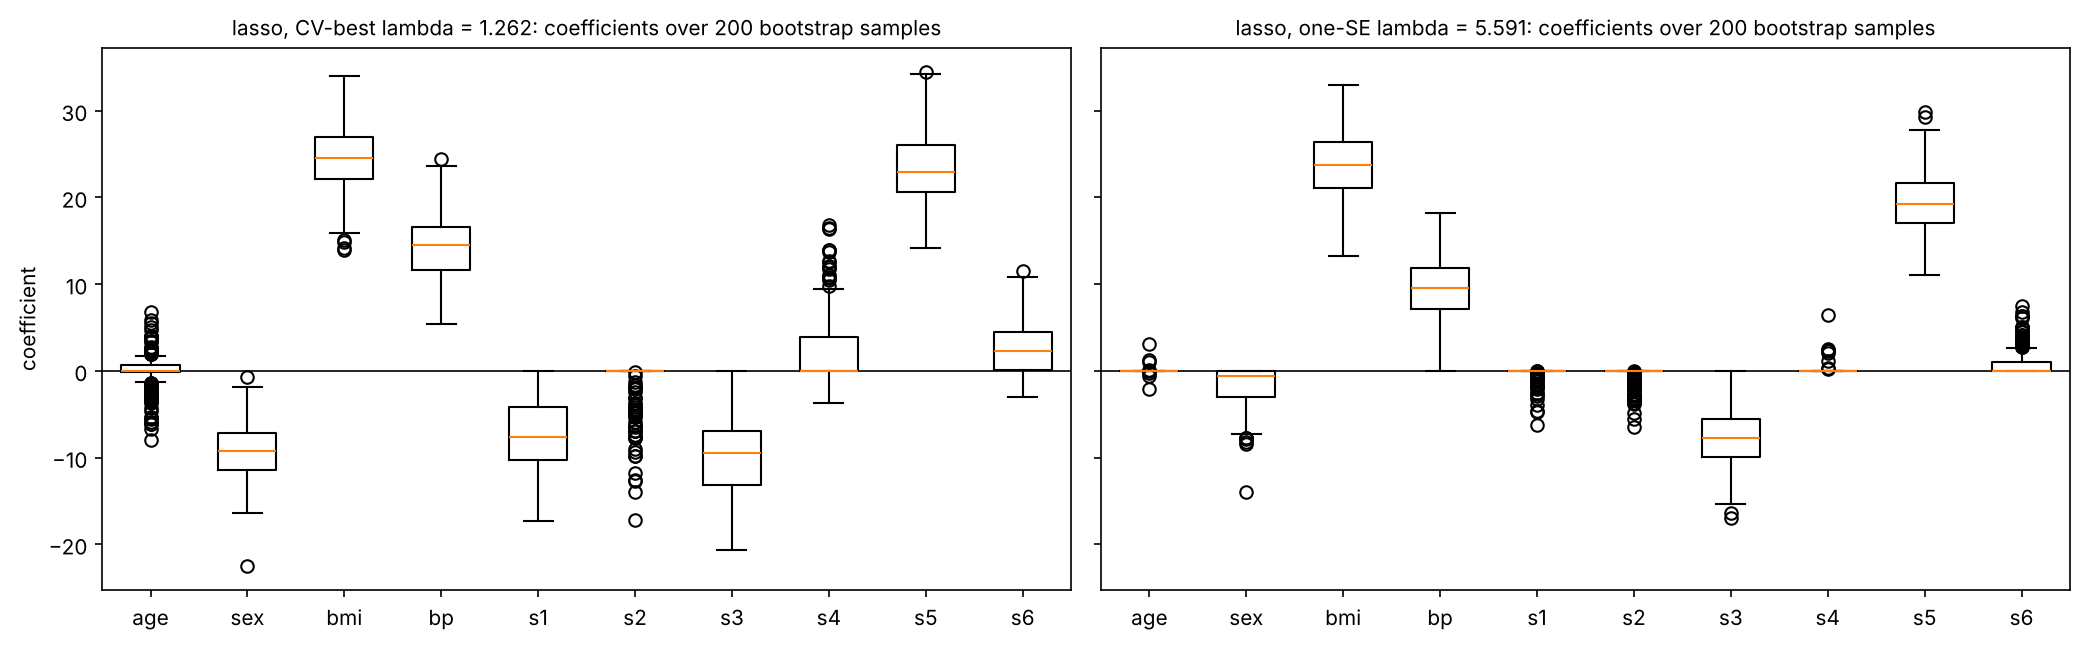

In [11]:
rs = np.random.RandomState(0)                        # the same seeded generator as in 7b: the same 200 samples
boot_best = np.empty((N_BOOT, p))                    # lasso coefficients at the CV-best lambda
boot_1se = np.empty((N_BOOT, p))                     # lasso coefficients at the one-SE lambda
for i in range(N_BOOT):
    idx = rs.randint(0, n_dev, size=n_dev)           # n_dev row numbers drawn WITH replacement
    Zb, yb = Z_dev[idx], y_dev[idx]                  # one bootstrap sample
    boot_best[i] = lasso_fit(Zb, yb, lam_lasso)[1]       # [1]: keep the coefficients, drop the intercept
    boot_1se[i] = lasso_fit(Zb, yb, lam_lasso_1se)[1]  # the same sample, one-SE lambda

stability = pd.DataFrame({                           # one row per feature
    "std at CV-best lambda": boot_best.std(axis=0),
    "std at one-SE lambda": boot_1se.std(axis=0),
    "fraction zero at CV-best": np.mean(boot_best == 0, axis=0),
    "fraction zero at one-SE": np.mean(boot_1se == 0, axis=0),
}, index=feature_names)
stability.loc["average"] = stability.mean()          # one more row with the column averages
display(stability.T)                                 # show it with the features across

def same_features(B, b_full):
    '''Fraction of bootstrap samples whose non-zero features are exactly those of the full-data fit.'''
    return np.mean([np.array_equal(row != 0, b_full != 0) for row in B])

print(f"samples that keep exactly the features of the full-data model:"
      f"  CV-best {same_features(boot_best, b_best):.1%},  one-SE {same_features(boot_1se, b_1se):.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)  # two panels, same scale
for ax, C, title in [(axes[0], boot_best, f"lasso, CV-best lambda = {lam_lasso:.3f}"),
                     (axes[1], boot_1se, f"lasso, one-SE lambda = {lam_lasso_1se:.3f}")]:
    ax.boxplot(C, widths=0.6)                        # one box per coefficient, over the 200 samples
    ax.set_xticks(range(1, p + 1))                   # boxes are drawn at positions 1..p
    ax.set_xticklabels(feature_names)                # label the boxes
    ax.axhline(0, color="black", lw=0.8)             # the zero line
    ax.set_title(f"{title}: coefficients over {N_BOOT} bootstrap samples", fontsize=10)
axes[0].set_ylabel("coefficient")                    # y-axis label, left panel only
plt.tight_layout()                                   # keep labels from overlapping
plt.show()                                           # draw the figure

**Line by line**

- `rs = np.random.RandomState(0)` : the same generator and seed as in 7b. Each pass of the loop draws the next 353
  row numbers, so the 200 samples are exactly the samples of 7b, and both values of $\lambda$ are fitted on the
  **same** samples: the comparison is fair.
- `rs.randint(0, n_dev, size=n_dev)` : 353 random row numbers from 0 to 352, with repeats allowed.
- `lasso_fit(Zb, yb, ...)[1]` : the coefficients only.
- `boot_best.std(axis=0)` : the standard deviation of each coefficient over the 200 samples (`axis=0` runs down the
  samples). This is how 7b measured stability.
- `np.mean(boot_best == 0, axis=0)` : for each coefficient, the fraction of samples in which it is exactly zero.
- `stability.loc["average"] = stability.mean()` : adds a row with the average of every column, as in 7b.
- `same_features(B, b_full)` : `row != 0` is the set of features a sample keeps, as a boolean mask;
  `np.array_equal` is `True` when it is identical to the mask of the full-data fit. The mean over the samples is the
  fraction of samples that keep exactly the same features.
- The box plots are those of 7b, for the two values of $\lambda$, on the same vertical scale (`sharey=True`).

**Reading the output.**

- At the CV-best $\lambda$, the average standard deviation of a coefficient is 3.57, the value of 7b. At the
  one-SE $\lambda$ it is **2.11**, about 40% lower: the more strongly penalised lasso is **more stable**.
- The gain comes from the correlated and weak features. The spread of `s1` falls from 4.47 to 0.84, `s4` from 4.03
  to 0.56, `s2` from 3.00 to 1.10 and `age` from 2.15 to 0.29: these coefficients are now zero in most samples (`age`
  and `s4` in 96%, `s1` in 86%, `s2` in 76%). The important features keep their spread (`bmi` 3.82 and 3.90, `bp` 3.51
  and 3.49), and `bmi` and `s5` are never zero.
- The **set** of selected features is also more stable: 26% of the samples keep exactly the full-data model's 5
  features, against 14.5% for the 7-feature model at the CV-best $\lambda$.
- One feature becomes **less** settled: `sex`, whose coefficient is close to the threshold, is zero in 41.5% of the
  samples at the one-SE $\lambda$ (never at the CV-best one).

**Answer.** At the one-standard-error $\lambda$ the lasso keeps 5 features (`sex, bmi, bp, s3, s5`) instead of 7, and
it is **more stable**: its coefficients vary about 40% less over the bootstrap samples, and it more often selects
exactly the same features. A simpler model is preferable when the CV errors cannot be told apart because:

- **the minimum is partly luck.** The CV-best $\lambda$ beats the one-SE $\lambda$ by about 150 (3074 against 3221),
  less than one standard error (161); another set of folds could have put the minimum elsewhere, and the smallest of
  100 noisy CV errors is optimistic for the $\lambda$ that achieved it (the winner's curse of Practical 4, 7f);
- **it varies less.** Stronger shrinkage lowers the variance of the fitted coefficients, which is exactly what the
  bootstrap measured, so the model is less likely to change with a new sample of patients;
- **it is easier to use and to explain.** Five coefficients, all clearly non-zero, tell a shorter and more reliable
  story than seven, two of which (`s1` and `s6`) are present in some samples and absent in others.

# Exercise 3: Choosing the subset size by cross-validation

**Task.**

1. For each of the 10 `folds`: standardise with the fold's training part, run `best_subset` on the training part
   only, and for every size $d$ compute the validation MSE of that fold's $M_d$ on the validation part.
2. Average over the folds to get a CV error for every $d$, and plot it with $\pm 1$ standard error. Which $d$ does
   cross-validation choose? Compare with AIC, BIC, $C_p$ and adjusted $R^2$ in 3c.
3. Why must `best_subset` be run again inside every fold, instead of using the models $M_d$ found on all the
   development rows?
4. Do the different folds choose the same features for $M_6$? Count how often each feature appears in $M_6$ over the
   10 folds.

**Concept.** In Part 3 the size $d$ was chosen by a **criterion**: training fit plus a penalty that estimates how much
the training fit flatters the model. Cross-validation estimates the test error **directly**, with no formula and no
assumptions about the noise, at the cost of more computation.

The important point is **what** is being cross-validated. "Best subset of size $d$" is not one fixed model, it is a
**procedure**: look at the training rows, try all $\binom{p}{d}$ subsets, keep the best, fit OLS on it. Choosing the
subset is part of training, so cross-validation must repeat the **whole** procedure inside every fold, using the
fold's training part only. A fold may then pick a different subset for the same $d$, and that is not a problem: it is
exactly the variability the CV error has to include.

## 3.1 and 3.2 Best subset inside every fold, and the CV error of every size

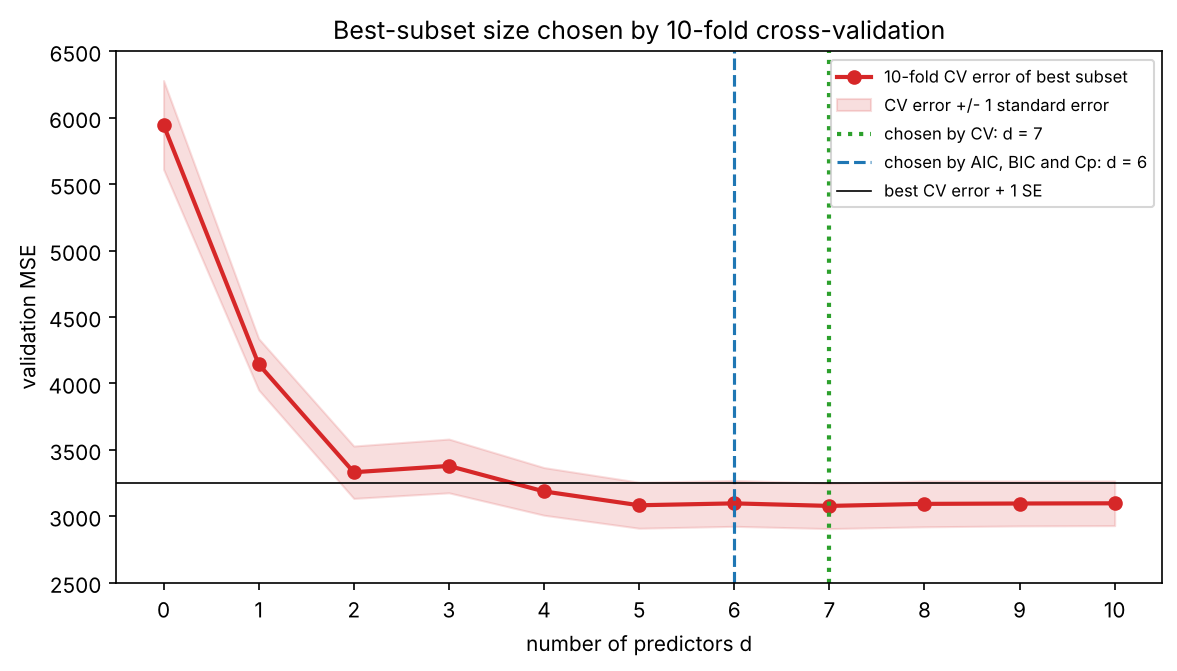

cross-validation chooses d = 7;   one-SE rule: d = 4;   criteria of 3c: {'AIC': 6, 'BIC': 6, 'Cp': 6, 'adj R^2': 7}


,CV error,standard error,M_d on all dev rows (Part 3)
d,,,
0,5946.0,334.7,
1,4144.1,193.4,bmi
2,3331.5,197.2,"bmi, s5"
3,3378.8,202.4,"bmi, bp, s5"
4,3187.1,179.4,"bmi, bp, s1, s5"
5,3082.8,173.1,"sex, bmi, bp, s3, s5"
6,3097.0,172.8,"sex, bmi, bp, s1, s2, s5"
7,3077.9,170.9,"sex, bmi, bp, s1, s2, s4, s5"
8,3093.2,172.5,"sex, bmi, bp, s1, s2, s4, s5, s6"


In [12]:
cv_subset = np.empty((p + 1, K))                    # validation MSE of M_d (row d) on fold f (column f)
fold_cols = []                                       # fold_cols[f][d] = the columns of M_d chosen in fold f
for f, (tr, va) in enumerate(folds):
    Z_tr = standardise(X_dev_raw[tr], X_dev_raw[tr]) # standardise with the fold's TRAINING part only
    Z_va = standardise(X_dev_raw[tr], X_dev_raw[va]) # the validation part, with the same statistics
    cols_f, _, _, _ = best_subset(Z_tr, y_dev[tr])   # 1024 fits on the training part only
    fold_cols.append(cols_f)                         # keep this fold's eleven models
    for d in range(p + 1):                           # for every size d ...
        b0, b = ols_fit(Z_tr[:, cols_f[d]], y_dev[tr])                          # ... refit M_d of this fold
        cv_subset[d, f] = mse(y_dev[va], predict(b0, b, Z_va[:, cols_f[d]]))   # ... and score it on the fold

cv_mean = cv_subset.mean(axis=1)                     # CV error of every size
cv_se = cv_subset.std(axis=1) / np.sqrt(K)           # its standard error
d_cv = int(np.argmin(cv_mean))                       # the size with the smallest CV error
d_cv_1se = int(np.flatnonzero(cv_mean <= cv_mean[d_cv] + cv_se[d_cv]).min())   # the one-SE rule: smallest such d

sizes = np.arange(p + 1)                             # d = 0, 1, ..., 10
fig, ax = plt.subplots(figsize=(9, 4.6))             # one panel
ax.plot(sizes, cv_mean, "o-", color="tab:red", lw=2, label="10-fold CV error of best subset")  # curve
ax.fill_between(sizes, cv_mean - cv_se, cv_mean + cv_se, color="tab:red", alpha=0.15,
                label="CV error +/- 1 standard error")
ax.axvline(d_cv, color="tab:green", ls="dotted", lw=2, label=f"chosen by CV: d = {d_cv}")  # CV choice
ax.axvline(best_d["BIC"], color="tab:blue", ls="dashed", lw=1.5, label=f"chosen by AIC, BIC and Cp: d = {best_d['BIC']}")
ax.axhline(cv_mean[d_cv] + cv_se[d_cv], color="black", lw=0.8, label="best CV error + 1 SE")  # threshold
ax.set_xticks(sizes)                                 # a tick at every size
ax.set_ylim(2500, 6500)                              # zoom on the useful range
ax.set_xlabel("number of predictors d")              # x-axis label
ax.set_ylabel("validation MSE")                      # y-axis label
ax.set_title("Best-subset size chosen by 10-fold cross-validation")  # title
ax.legend(fontsize=8)                                # legend
plt.show()                                           # draw the figure

compare = pd.DataFrame({"CV error": cv_mean, "standard error": cv_se,  # one row per size
                        "M_d on all dev rows (Part 3)": bs_table["features"]}, index=pd.Index(sizes, name="d"))
print(f"cross-validation chooses d = {d_cv};   one-SE rule: d = {d_cv_1se};   criteria of 3c: {best_d}")
compare.round(1)                                     # display, one decimal

**Line by line**

- `cv_subset = np.empty((p + 1, K))` : an $11 \times 10$ table, one row per size $d = 0, \dots, 10$ and one column per
  fold.
- `for f, (tr, va) in enumerate(folds):` : the ten folds of 6b, so the CV errors here can be compared with those of
  ridge and the lasso.
- `standardise(X_dev_raw[tr], ...)` : as in `cv_errors` (6b), the mean and standard deviation come from the fold's
  training part only, and are applied to both parts.
- `cols_f, _, _, _ = best_subset(Z_tr, y_dev[tr])` : the whole best-subset search on the training part of this fold.
  The function returns four things; we keep only the first (the best columns for every size) and send the other
  three to `_`.
- `fold_cols.append(cols_f)` : remembers this fold's eleven models for step 4.
- The inner loop refits $M_d$ of this fold on its training part and computes its MSE on the validation part.
  (`best_subset` does not return the coefficients, only the columns, so we refit; it is the same OLS fit.)
- `cv_subset.mean(axis=1)` and `.std(axis=1) / np.sqrt(K)` : CV error and standard error of every size, as in 6b.
- `np.flatnonzero(cv_mean <= threshold).min()` : the one-standard-error rule. For subsets "simplest" means
  **fewest** predictors, so we take the **smallest** $d$ under the threshold.
- The figure is drawn as in 6b. `ax.set_ylim(2500, 6500)` keeps the useful part of the curve readable; the empty
  model ($d = 0$, CV error about 5946) is at the top edge.
- `pd.Index(sizes, name="d")` : row labels $0, \dots, 10$ with the heading `d`. The last column shows $M_d$ from
  Part 3, for reference.

**Reading the plot and the table.**

- The CV error falls steeply from $d = 0$ (5946) to $d = 2$ (3332), then more slowly, and from $d = 5$ on it is
  **flat**: every size from 5 to 10 has a CV error between 3078 and 3098, while the standard errors are about 170.
- Cross-validation chooses **$d = 7$** (CV error 3077.9). AIC, BIC and $C_p$ chose $d = 6$ in 3c, and adjusted $R^2$
  chose $d = 7$. The CV error of $d = 6$ is 3097.0, only 19 higher: the difference between 6 and 7 is a small
  fraction of one standard error, so all these choices are, statistically, the same.
- The one-standard-error rule picks **$d = 4$** (3187.1, under the threshold of 3248.8). That is a smaller model than
  any criterion chose, in line with Exercise 2.
- One oddity: $d = 3$ (3378.8) has a higher CV error than $d = 2$ (3331.5). Inside the folds, the best set of three
  features is not always the same, and in some folds it generalises worse than the pair `bmi, s5`. With only 35 or 36
  validation rows per fold, such bumps are within the noise.
- The best CV errors here (about 3078) are almost exactly those of ridge (3084) and the lasso (3074) in 6b. On ten
  features, all the methods predict about equally well, as Part 7 also found.

## 3.3 Why `best_subset` must be run inside every fold

To see the answer, compare with the shortcut: take the models $M_d$ that best subset found on **all** development rows
(Part 3), and cross-validate only the refitting of their coefficients.

In [13]:
cv_shortcut = np.empty((p + 1, K))                  # the shortcut: subsets chosen ONCE, on all development rows
for f, (tr, va) in enumerate(folds):
    Z_tr = standardise(X_dev_raw[tr], X_dev_raw[tr])  # training part, its own statistics
    Z_va = standardise(X_dev_raw[tr], X_dev_raw[va])  # validation part, training statistics
    for d in range(p + 1):
        b0, b = ols_fit(Z_tr[:, bs_cols[d]], y_dev[tr])                         # M_d of Part 3, refitted ...
        cv_shortcut[d, f] = mse(y_dev[va], predict(b0, b, Z_va[:, bs_cols[d]])) # ... and scored on the fold

same_subset = [sum(fold_cols[f][d] == bs_cols[d] for f in range(K)) for d in range(p + 1)]   # folds agreeing with Part 3
leak = pd.DataFrame({"honest CV (selection inside each fold)": cv_mean,  # side by side
                     "shortcut CV (subsets chosen on all rows)": cv_shortcut.mean(axis=1),
                     "shortcut is lower by": cv_mean - cv_shortcut.mean(axis=1),
                     "folds whose M_d equals Part 3's M_d": same_subset}, index=pd.Index(sizes, name="d"))
leak.round(1)                                        # display, one decimal

,honest CV (selection inside each fold),shortcut CV (subsets chosen on all rows),shortcut is lower by,folds whose M_d equals Part 3's M_d
d,,,,
0,5946.0,5946.0,0.0,10
1,4144.1,4003.7,140.4,9
2,3331.5,3331.5,0.0,10
3,3378.8,3237.3,141.5,7
4,3187.1,3154.6,32.5,9
5,3082.8,3082.8,0.0,10
6,3097.0,3039.0,58.0,6
7,3077.9,3051.5,26.4,6
8,3093.2,3060.0,33.2,6


**Line by line**

- The loop is the loop of 3.1 without the call to `best_subset`: every fold uses `bs_cols[d]`, the subsets chosen in
  Part 3 from all 353 development rows, including the rows that are now the validation part.
- `fold_cols[f][d] == bs_cols[d]` : `True` when fold `f` chose the same subset of size `d` as Part 3; Python's `sum`
  counts the `True` values over the ten folds.
- `cv_mean - cv_shortcut.mean(axis=1)` : positive values mean that the shortcut looks better than the honest estimate.

**Reading the output.** Where every fold chose the same subset as Part 3 ($d = 0, 2, 5, 10$), the two estimates are
identical. Wherever some folds chose differently, the shortcut is **lower**: by about 140 for $d = 1$ and for
$d = 3$, 58 for $d = 6$ and between 14 and 33 for the other sizes. It never comes out higher.

**Answer.** The models $M_d$ of Part 3 were chosen by looking at all 353 development rows, so in every fold the
validation rows have **already helped to choose the subset** that is then evaluated on them. That is leakage,
exactly as in Practical 4, Exercise 4, where features chosen on all rows made pure noise look predictive. The
subset that wins on all rows is partly the subset that happens to fit these particular rows well, including each
fold's validation rows, so the shortcut's CV error is too optimistic. The honest estimate must cover everything that
learns from the data, and here choosing the subset is part of learning. Hence `best_subset` must run again, on the
training part only, inside every fold, and the table shows the size of the optimism it removes.

## 3.4 Do the folds agree on $M_6$?

In [14]:
m6_by_fold = pd.DataFrame({"features of M_6": [", ".join(feature_names[fold_cols[f][6]]) for f in range(K)]},
                          index=pd.Index(range(1, K + 1), name="fold"))
display(m6_by_fold)                                  # one row per fold

counts = pd.Series({name: sum(name in feature_names[fold_cols[f][6]] for f in range(K)) for name in feature_names},
                   name="folds (out of 10) in which the feature is in M_6")
print("M_6 found on all development rows (Part 3):", ", ".join(feature_names[bs_cols[6]]))
print("number of different M_6 over the 10 folds  :", len({tuple(fold_cols[f][6]) for f in range(K)}))
counts.to_frame().T                                  # display, features across the page

,features of M_6
fold,
1,"sex, bmi, bp, s1, s2, s5"
2,"sex, bmi, bp, s1, s2, s5"
3,"sex, bmi, bp, s1, s2, s5"
4,"sex, bmi, bp, s1, s2, s5"
5,"sex, bmi, bp, s1, s2, s5"
6,"sex, bmi, bp, s1, s2, s5"
7,"sex, bmi, bp, s1, s4, s5"
8,"sex, bmi, bp, s1, s4, s5"
9,"sex, bmi, bp, s1, s3, s5"


M_6 found on all development rows (Part 3): sex, bmi, bp, s1, s2, s5
number of different M_6 over the 10 folds  : 3


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
folds (out of 10) in which the feature is in M_6,0,10,10,10,10,6,1,3,10,0


**Line by line**

- `fold_cols[f][6]` : the columns of the best 6-feature model found in fold `f`; `feature_names[...]` turns them into
  names and `", ".join(...)` into one string.
- `pd.Index(range(1, K + 1), name="fold")` : number the folds from 1 to 10 for display.
- `name in feature_names[fold_cols[f][6]]` : `True` if the feature is in that fold's $M_6$. The dictionary
  comprehension counts this over the ten folds for every feature.
- `{tuple(fold_cols[f][6]) for f in range(K)}` : a **set** of the ten subsets. Lists cannot be put in a set, so
  each is turned into a tuple first; the size of the set is the number of **different** subsets.

**Reading the output.**

- `sex, bmi, bp, s1, s5` are in $M_6$ in **all ten folds**. `age` and `s6` are in none.
- The sixth place changes: `s2` in 6 folds (as in Part 3), `s4` in 3 folds and `s3` in 1. So there are **3 different**
  $M_6$ over the ten folds.

**Answer.** No, the folds do not all choose the same $M_6$. They agree completely on five features, which are the
features that matter most (they were also the first five added by forward selection in Part 4). They disagree only
on the sixth, which rotates among `s2`, `s4` and `s3`: the tangled group of cholesterol measurements of 1c. Removing
a tenth of the rows is enough to change which member of the correlated group looks best. This is the same instability
that the bootstrap showed for OLS coefficients in 7b, now appearing as instability of the **selection**.

# Exercise 4: The elastic net

**Task.**

1. Copy `lasso_fit` into `elastic_net_fit(Z, y, lam, l1_ratio)` and change the update line. Check it against
   `ElasticNet(alpha=lam, l1_ratio=l1_ratio, tol=1e-10, max_iter=100000)` for several values of `lam` and `l1_ratio`.
2. Check that `l1_ratio=1` gives exactly `lasso_fit`, and that `l1_ratio=0` gives `ridge_fit` with a ridge $\lambda$ of
   $n\lambda$. Explain the factor $n$ by comparing the two objectives.
3. Repeat part 4 of Exercise 1 with `l1_ratio=0.5`. How is the weight now split between the two copies of `s1`? Why is
   the elastic net often preferred to the lasso when predictors come in correlated groups?

**Concept.** The elastic net minimises, in scikit-learn's scaling,

$$\frac{1}{2n}\,\text{RSS} + \lambda\,\alpha \sum_j \lvert\beta_j\rvert + \frac{\lambda\,(1-\alpha)}{2} \sum_j \beta_j^2,$$

with $\alpha$ (`l1_ratio`) between 0 and 1: $\alpha = 1$ is the lasso, $\alpha = 0$ is a ridge penalty, and values in
between mix the two.

**Where the new update comes from.** Coordinate descent again holds every coefficient except $\beta_j$ fixed. With
$c_j = \frac1n x_j^{\top}x_j$ (1 for a standardised column) and $\rho_j$ exactly as in 5b, the one-coefficient problem
of the lasso was $\frac{c_j}{2}\beta_j^2 - \rho_j\beta_j + \lambda\lvert\beta_j\rvert$. The elastic net changes the
absolute-value penalty to $\lambda\alpha\lvert\beta_j\rvert$ and adds $\frac{\lambda(1-\alpha)}{2}\beta_j^2$, which
simply joins the quadratic term:

$$\frac{c_j + \lambda(1-\alpha)}{2}\,\beta_j^2 - \rho_j\beta_j + \lambda\alpha\lvert\beta_j\rvert
\quad\Longrightarrow\quad
\beta_j = \frac{S(\rho_j,\ \lambda\alpha)}{c_j + \lambda(1-\alpha)} .$$

The numerator is the lasso's soft threshold with a smaller threshold $\lambda\alpha$ (it still produces exact zeros);
the denominator is larger than $c_j$, which shrinks every non-zero coefficient a little further, like ridge.

## 4.1 The elastic net from scratch, checked against `ElasticNet`

In [15]:
from sklearn.linear_model import ElasticNet          # the library elastic net, used only to check


def elastic_net_fit(Z, y, lam, l1_ratio, b_start=None, tol=1e-8, max_sweeps=100000):
    '''Elastic net by coordinate descent: (1/2n) RSS + lam*l1_ratio*sum|b_j| + lam*(1-l1_ratio)/2*sum b_j^2.

    l1_ratio = 1 is the lasso, l1_ratio = 0 is ridge. returns (b0, b), the intercept and the coefficients
    '''
    n, p = Z.shape                                   # rows and columns
    z_mean, y_mean = Z.mean(axis=0), y.mean()        # column means and target mean
    Zc, yc = Z - z_mean, y - y_mean                 # centre, so the intercept can be found at the end
    col_sq = (Zc ** 2).mean(axis=0)                 # (1/n) x_j^T x_j for every column: 1 if standardised
    b = np.zeros(p) if b_start is None else b_start.copy()   # start from zeros, or from a warm start
    r = yc - Zc @ b                                 # the full residual of the current model
    for sweep in range(max_sweeps):
        biggest_change = 0.0                         # largest change in this sweep
        for j in range(p):
            rho = Zc[:, j] @ r / n + col_sq[j] * b[j]           # exactly as in lasso_fit
            new_bj = soft_threshold(rho, lam * l1_ratio) / (col_sq[j] + lam * (1 - l1_ratio))   # THE changed line
            change = new_bj - b[j]                   # how much b_j moves
            if change != 0.0:
                r -= Zc[:, j] * change                          # keep the residual up to date
                b[j] = new_bj                        # store the new value
                biggest_change = max(biggest_change, abs(change))  # track the largest move
        if biggest_change < tol:                                # a whole sweep with (almost) no change: done
            break                                    # converged: leave the loop
    b0 = y_mean - z_mean @ b                        # the intercept puts the fit through the means
    return b0, b


rows = []                                            # one dictionary per row of the table
for lam in [0.01, 0.1, 1, 5]:                        # four penalty strengths ...
    for l1_ratio in [0.1, 0.5, 0.9]:                 # ... times three mixtures
        b0, b = elastic_net_fit(Z_dev, y_dev, lam, l1_ratio)  # our elastic net
        lib = ElasticNet(alpha=lam, l1_ratio=l1_ratio, tol=1e-10, max_iter=100000).fit(Z_dev, y_dev)  # library
        rows.append({"lambda": lam, "l1_ratio": l1_ratio,  # one row per pair of settings
                     "same as ElasticNet": np.allclose(b, lib.coef_, atol=1e-6) and np.isclose(b0, lib.intercept_),
                     "largest difference": np.abs(b - lib.coef_).max(),
                     "zero coefficients": int(np.sum(b == 0))})
pd.DataFrame(rows).set_index(["lambda", "l1_ratio"])  # grouped by lambda

same as ElasticNet  largest difference  zero coefficients
lambda l1_ratio                                                           
0.01   0.1                     True          2.1450e-07                  0
       0.5                     True          2.7328e-07                  0
       0.9                     True          3.7378e-07                  0
0.10   0.1                     True          3.6501e-08                  0
       0.5                     True          5.9129e-08                  1
       0.9                     True          2.0849e-07                  1
1.00   0.1                     True          2.8235e-09                  0
       0.5                     True          2.5760e-09                  0
       0.9                     True          3.0425e-08                  1
5.00   0.1                     True          3.9161e-10                  0
       0.5                     True          4.9156e-10                  1
       0.9                     True          1.4925e-09                  3

**Line by line**

- `from sklearn.linear_model import ElasticNet` : the import the exercise asks for. Like `Lasso`, it calls the
  penalty strength `alpha`; its mixing parameter is `l1_ratio`.
- `elastic_net_fit(...)` : a copy of `lasso_fit` (5c), line for line, except:
  - the extra argument `l1_ratio`;
  - **the update line**: `soft_threshold(rho, lam * l1_ratio)` thresholds at $\lambda\alpha$ instead of $\lambda$,
    and the result is divided by `col_sq[j] + lam * (1 - l1_ratio)` instead of `col_sq[j]`. This is the formula
    derived above.
- Everything else (centring, `col_sq`, the running residual `r`, the stopping rule, the intercept) is unchanged,
  because the ridge part of the penalty does not touch the RSS term.
- The double loop checks 4 values of $\lambda$ times 3 values of `l1_ratio`, 12 cases in all.
- `ElasticNet(alpha=lam, l1_ratio=l1_ratio, tol=1e-10, max_iter=100000)` : the library version with a tight
  tolerance, as for `Lasso` in 5c.
- `np.allclose(b, lib.coef_, atol=1e-6)` : two iterative solvers stop at slightly different points, so differences
  below $10^{-6}$ are accepted, as in 5c.
- `set_index(["lambda", "l1_ratio"])` : a two-level row label, so the table is grouped by $\lambda$.

**Reading the output.** All 12 rows print `True`, with differences below $4 \times 10^{-7}$. Changing one line of
`lasso_fit` gives exactly scikit-learn's elastic net. The number of exact zeros depends on both settings: it grows
with $\lambda$ and with `l1_ratio` (3 zeros at $\lambda = 5$, `l1_ratio` $= 0.9$, none with `l1_ratio` $= 0.1$),
because only the $\ell_1$ part, of strength $\lambda\alpha$, can set coefficients to zero.

## 4.2 The two extremes: the lasso and ridge

In [16]:
rows = []                                   # one dictionary per row of the table
for lam in [0.1, 1, 5]:
    b_en1 = elastic_net_fit(Z_dev, y_dev, lam, 1.0)[1]          # l1_ratio = 1
    b_lasso = lasso_fit(Z_dev, y_dev, lam)[1]                   # the lasso of 5c
    b0_en0, b_en0 = elastic_net_fit(Z_dev, y_dev, lam, 0.0)     # l1_ratio = 0
    b0_rid, b_rid = ridge_fit(Z_dev, y_dev, n_dev * lam)        # ridge with lambda multiplied by n
    rows.append({"lambda": lam,                      # one row per lambda
                 "l1_ratio = 1: identical to lasso_fit": np.array_equal(b_en1, b_lasso),
                 "ridge lambda = n * lambda": n_dev * lam,
                 "l1_ratio = 0: same as ridge_fit(n * lambda)": np.allclose(b_en0, b_rid, atol=1e-6)
                                                                and np.isclose(b0_en0, b0_rid),
                 "largest difference from ridge": np.abs(b_en0 - b_rid).max()})
pd.DataFrame(rows).set_index("lambda")               # display the table

,l1_ratio = 1: identical to lasso_fit,ridge lambda = n * lambda,l1_ratio = 0: same as ridge_fit(n * lambda),largest difference from ridge
lambda,,,,
0.1,True,35.3,True,3.7720e-08
1.0,True,353.0,True,8.0365e-10
5.0,True,1765.0,True,1.5400e-10


**Line by line**

- `elastic_net_fit(Z_dev, y_dev, lam, 1.0)[1]` : the elastic net with `l1_ratio = 1`; `[1]` keeps the coefficients.
- `np.array_equal(b_en1, b_lasso)` : a stricter test than `np.allclose`: `True` only if every number is **exactly**
  the same, to the last bit.
- `ridge_fit(Z_dev, y_dev, n_dev * lam)` : closed-form ridge, with its $\lambda$ set to $n\lambda = 353\lambda$.
- `np.allclose(..., atol=1e-6)` : coordinate descent stops within its tolerance of the exact ridge solution, so here we
  accept tiny differences.

**Reading the output.**

- With `l1_ratio = 1` the elastic net is **bit for bit** identical to `lasso_fit` at every $\lambda$: the update
  becomes `soft_threshold(rho, lam) / (col_sq[j] + 0)`, exactly the lasso's arithmetic.
- With `l1_ratio = 0` it agrees with ridge at $\lambda_{\text{ridge}} = 35.3$, 353 and 1765, that is $n\lambda$, with
  differences below $10^{-7}$.

**Answer: the factor $n$.** With `l1_ratio = 0` the elastic net minimises

$$\frac{1}{2n}\,\text{RSS} + \frac{\lambda}{2}\sum_j \beta_j^2 .$$

Multiplying an objective by a positive constant does not move its minimum. Multiplying by $2n$ gives

$$\text{RSS} + n\lambda \sum_j \beta_j^2 ,$$

which is the ridge objective of 5a with $\lambda_{\text{ridge}} = n\lambda$. The factor appears because scikit-learn's
`Lasso` and `ElasticNet` divide the RSS by $2n$ while `Ridge` does not divide it at all; it is the same difference in
scaling that 5b mentioned to explain why the lasso and ridge grids of Part 6 cover different ranges. (The factor 2 is
absorbed by the $\frac{1}{2}$ in front of the ridge part of the elastic net penalty.)

## 4.3 Two identical columns under the elastic net

elastic net, copy at the back : s1 -1.025421,  copy -1.025421
elastic net, copy at the front: s1 -1.025421,  copy -1.025421
sklearn ElasticNet, at the back: s1 -1.025421,  copy -1.025421
(lasso of Exercise 1: back -0.0269 / -7.4696,  front -2.0731 / -5.4235)


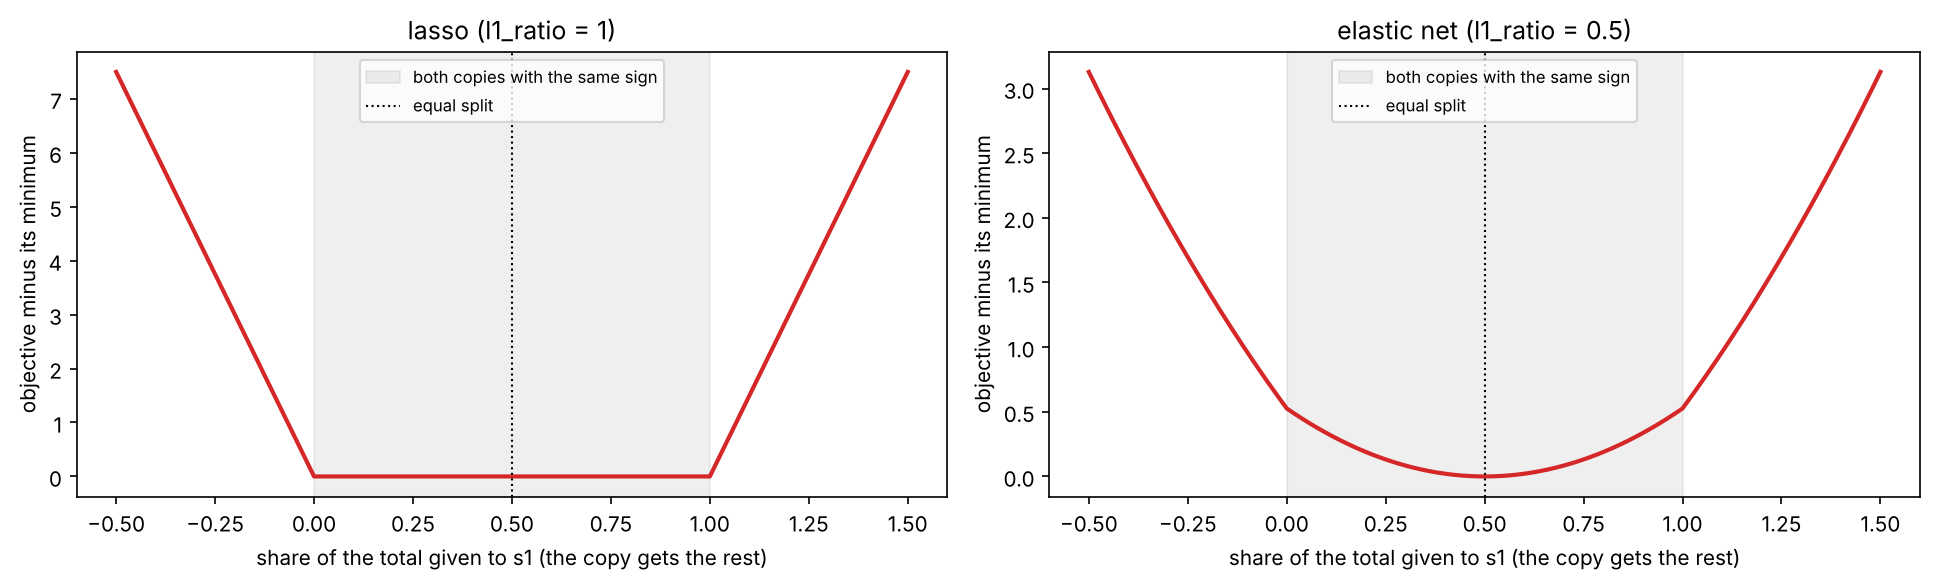

In [17]:
lam, l1_ratio = 1.0, 0.5                             # the lambda of Exercise 1, and an even mixture
b0_en_back, b_en_back = elastic_net_fit(Z_dup, y_dev, lam, l1_ratio)       # copy at the back (column 10)
b0_en_front, b_en_front = elastic_net_fit(Z_front, y_dev, lam, l1_ratio)   # copy at the front (column 0)
lib_en = ElasticNet(alpha=lam, l1_ratio=l1_ratio, tol=1e-10, max_iter=100000).fit(Z_dup, y_dev)  # library

print(f"elastic net, copy at the back : s1 {b_en_back[4]:.6f},  copy {b_en_back[10]:.6f}")
print(f"elastic net, copy at the front: s1 {b_en_front[5]:.6f},  copy {b_en_front[0]:.6f}")
print(f"sklearn ElasticNet, at the back: s1 {lib_en.coef_[4]:.6f},  copy {lib_en.coef_[10]:.6f}")
print(f"(lasso of Exercise 1: back {b_back[4]:.4f} / {b_back[10]:.4f},  front {b_front[5]:.4f} / {b_front[0]:.4f})")


def elastic_net_objective(Z, y, b0, b, lam, l1_ratio):
    '''(1/2n) RSS + lam * l1_ratio * sum|b_j| + lam * (1 - l1_ratio) / 2 * sum b_j^2.'''
    return (np.sum((y - b0 - Z @ b) ** 2) / (2 * len(y)) + lam * l1_ratio * np.sum(np.abs(b))
            + lam * (1 - l1_ratio) / 2 * np.sum(b ** 2))


# the objective along every way of splitting the same total between s1 and its copy
shares = np.linspace(-0.5, 1.5, 201)                 # fraction of the total given to s1
curves = {}                                          # one curve per method
for name, b0_fit, b_fit, mix in [("lasso (l1_ratio = 1)", b0_back, b_back, 1.0),
                                 ("elastic net (l1_ratio = 0.5)", b0_en_back, b_en_back, 0.5)]:
    total = b_fit[4] + b_fit[10]                     # the combined effect of s1, fixed
    values = []                                      # objective for every share
    for share in shares:
        b_try = b_fit.copy()                         # start from the fitted coefficients
        b_try[4], b_try[10] = share * total, (1 - share) * total     # split the total in this proportion
        values.append(elastic_net_objective(Z_dup, y_dev, b0_fit, b_try, lam, mix))  # score this split
    curves[name] = np.array(values) - min(values)    # measured from the curve's own minimum

fig, axes = plt.subplots(1, 2, figsize=(13, 4))      # two panels
for ax, (name, values) in zip(axes, curves.items()):
    ax.plot(shares, values, color="tab:red", lw=2)   # the objective curve
    ax.axvspan(0, 1, color="tab:grey", alpha=0.12, label="both copies with the same sign")  # shade 0 to 1
    ax.axvline(0.5, color="black", ls="dotted", lw=1, label="equal split")  # mark 0.5
    ax.set_xlabel("share of the total given to s1 (the copy gets the rest)")  # x-axis label
    ax.set_ylabel("objective minus its minimum")     # y-axis label
    ax.set_title(name)                               # panel title
    ax.legend(fontsize=8, loc="upper center")        # legend
plt.tight_layout()                                   # keep labels from overlapping
plt.show()                                           # draw the figure

**Line by line**

- `Z_dup` and `Z_front` are the two matrices of Exercise 1 (copy at the back, copy at the front); `b_back` and
  `b_front` are the lasso fits of Exercise 1, printed again for comparison.
- `elastic_net_fit(..., lam, l1_ratio)` with $\lambda = 1$ and `l1_ratio` $= 0.5$ : half lasso, half ridge.
- `elastic_net_objective(...)` : the function the elastic net minimises, written out so we can evaluate it at any
  coefficients.
- `np.linspace(-0.5, 1.5, 201)` : 201 shares from $-0.5$ to $1.5$. A share between 0 and 1 gives both copies the same
  sign; outside that range the two copies have opposite signs.
- The loop does what the second table of Exercise 1, step 4 did, but for many shares and for both methods: keep every
  other coefficient at its fitted value, keep the total effect of `s1` fixed, and only change how it is split.
- `np.array(values) - min(values)` : each curve is shifted so that its lowest point is 0, which makes the two shapes
  easy to compare.
- `ax.axvspan(0, 1, ...)` : shades the range of shares in which both copies have the same sign.

**Reading the output and the plot.**

- With `l1_ratio = 0.5` both copies get **the same coefficient**, $-1.0254$ (equal to six decimals), whether the copy is at the back
  or at the front, and `ElasticNet` agrees. The lasso of Exercise 1 had given $-0.03$ and $-7.47$ in one order and
  $-2.07$ and $-5.42$ in the other.
- The left panel shows why the lasso could not decide: its objective is **completely flat** over the whole shaded
  range. Every same-sign split is equally good.
- The right panel shows why the elastic net can: the small ridge part turns the flat stretch into a **bowl** with a
  single lowest point, at the equal split (share 0.5).
- The coefficients are much smaller than the lasso's at the same $\lambda$, because the ridge part
  $\frac{\lambda(1-\alpha)}{2}\sum\beta_j^2$ with $\lambda(1 - \alpha) = 0.5$ corresponds to a ridge $\lambda$ of
  $n \times 0.5 \approx 177$ (4.2), a strong penalty on its own.

**Answer.** Under the elastic net the weight is split **equally** between the two copies, in either column order.
The ridge part of the penalty is strictly convex: for a fixed total, $\beta_{s1}^2 + \beta_{\text{copy}}^2$ is
smallest at the equal split (Exercise 1, step 3), so the objective has a single minimum, and because swapping two
identical columns cannot change the objective, that minimum must be symmetric.

This is why the elastic net is often preferred when predictors come in **correlated groups**:

- **It has a unique, stable answer.** The lasso's choice within a group is decided by accidents (column order,
  starting point, small changes in the sample, Exercise 1); the elastic net's is not.
- **It keeps or drops a correlated group together** (the *grouping effect*). Highly correlated features get similar
  coefficients, so the model says "this group of cholesterol measurements matters" instead of crediting one
  arbitrary member and zeroing the rest.
- **It still selects.** The $\ell_1$ part still sets the coefficients of unimportant features (and whole unimportant
  groups) to exactly zero, so the model stays sparse, which pure ridge never does.

In practice both $\lambda$ and `l1_ratio` are chosen by cross-validation, exactly as $\lambda$ was in Part 6.

# Exercise 5: Forward stepwise on the 55 features

**Task.**

1. Run `forward_stepwise(Z55_dev, y_dev)`. How many models does it fit? How long does it take?
2. For every size compute BIC with `criteria`, passing `n`, `tss` and `sigma2` explicitly, with `sigma2` estimated
   from the full 55-feature OLS model. Which size does BIC choose, and which features?
3. Compare the BIC-chosen features with the 20 features kept by the lasso in 7c. How many do they share?
4. Fit OLS on the BIC-chosen subset of the development rows and compute its test MSE. Add it as a fourth row to the
   55-feature results of 7c. How does greedy subset selection compare with the lasso here, in test error and in the
   size of its coefficients?

**Concept.** With 55 predictors, best subset would need $2^{55} \approx 3.6 \times 10^{16}$ fits (4c), but forward
stepwise needs only $1 + 55 \cdot 56/2 = 1541$. It gives one model for every size $d = 0, \dots, 55$, and a criterion
then chooses between them, as in Part 3. The comparison with the lasso in step 4 is the comparison of the two
families of the practical on the hard problem: **selection** (all-or-nothing, then plain OLS) against **shrinkage**.

## 5.1 Forward stepwise on 55 predictors

In [18]:
import time                                          # Python's standard module for measuring time

start = time.perf_counter()                          # read a high-resolution clock (in seconds)
fw55_cols, fw55_fits = forward_stepwise(Z55_dev, y_dev)   # one model of every size, 0 to 55
seconds = time.perf_counter() - start                # elapsed time = second reading minus first reading

print(f"models fitted: {fw55_fits}   (formula 1 + p(p+1)/2 = {1 + p55 * (p55 + 1) // 2};  best subset: 2^55)")
print(f"time taken   : {seconds:.2f} seconds  ({1000 * seconds / fw55_fits:.3f} ms per fit)")
added55 = [(set(fw55_cols[d]) - set(fw55_cols[d - 1])).pop() for d in range(1, p55 + 1)]   # the order of entry
print("\nthe first 12 features added:", " > ".join(names55[added55[:12]]))

models fitted: 1541   (formula 1 + p(p+1)/2 = 1541;  best subset: 2^55)
time taken   : 0.13 seconds  (0.086 ms per fit)

the first 12 features added: bmi > s5 > age sex > bp > s1 > sex > s2 > bmi bp > s4 s6 > s1 s4 > sex s3 > s2 s4


**Line by line**

- `import time` and `time.perf_counter()` : the import and the clock the exercise asks for. Only the **difference**
  between two readings means anything: the run time in seconds.
- `forward_stepwise(Z55_dev, y_dev)` : the function of 4a, unchanged, on the 55 standardised columns. It returns the
  path (`fw55_cols[d]` = the columns of the model with $d$ predictors) and the number of OLS fits.
- `1 + p55 * (p55 + 1) // 2` : the formula of 4a, with `//` for integer division.
- `set(fw55_cols[d]) - set(fw55_cols[d - 1])` : the one column that is in the model of size $d$ but not in the one of
  size $d - 1$, i.e. the column added at step $d$ (the same trick as in 4a). `.pop()` takes it out of the set.
- `names55[added55[:12]]` : the names of the first 12 columns added, and `" > ".join(...)` writes them in order.

**Reading the output.** Forward stepwise fits **1541** models, exactly the formula, in a fraction of a second (the
exact time depends on the computer). Best subset would have needed $2^{55}$ fits, more than a million years at this
speed. The first features to enter are the important main effects of Parts 3 and 4 (`bmi`, `s5`, `bp`, `s1`, `sex`),
but the interaction `age sex` already comes **third**.

## 5.2 BIC for every size, with the right default values

BIC chooses d = 8: sex, bmi, bp, s1, s2, s5, age sex, bmi bp
for comparison: AIC chooses d = 15,  Cp d = 15,  adjusted R^2 d = 20

Cp of the full 55-feature model: 56.00 with sigma2 from the 55-feature model (must be p + 1 = 56),  38.77 with the default sigma2
default sigma2 = 2994.3 (10-feature model),  correct sigma2 = 2820.6 (55-feature model)


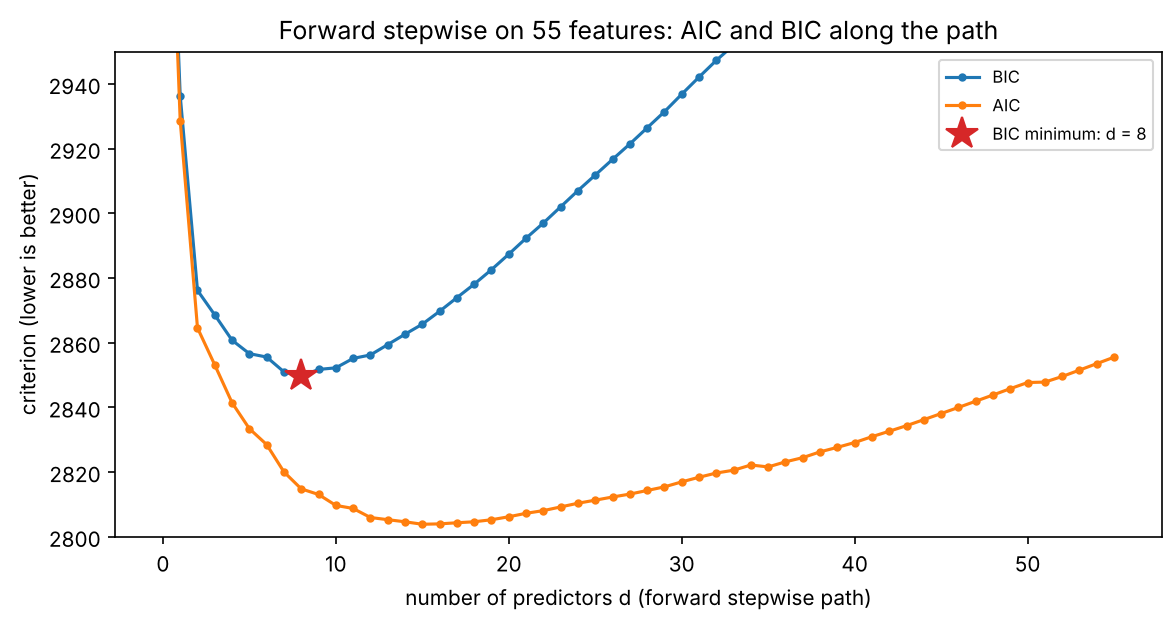

In [19]:
rss55 = np.array([rss(Z55_dev, y_dev, fw55_cols[d]) for d in range(p55 + 1)])   # RSS of the model of every size
rss55_full = rss55[p55]                              # the full model with all 55 predictors
sigma2_55 = rss55_full / (n_dev - p55 - 1)           # noise variance estimated from the FULL 55-feature model
tss55 = np.sum((y_dev - y_dev.mean()) ** 2)          # total sum of squares of the development targets

crit55 = pd.DataFrame([criteria(rss55[d], d, n=n_dev, tss=tss55, sigma2=sigma2_55)        # every argument explicit
                       for d in range(p55 + 1)], index=pd.Index(range(p55 + 1), name="d"))
d_bic = int(crit55["BIC"].idxmin())                  # the size chosen by BIC
bic_cols = fw55_cols[d_bic]                          # its columns

print(f"BIC chooses d = {d_bic}:", ", ".join(names55[bic_cols]))
print(f"for comparison: AIC chooses d = {crit55['AIC'].idxmin()},  Cp d = {crit55['Cp'].idxmin()},"
      f"  adjusted R^2 d = {crit55['adj R^2'].idxmax()}")

# what the default values would have done
crit_defaults = pd.DataFrame([criteria(rss55[d], d) for d in range(p55 + 1)])  # WRONG: defaults
print(f"\nCp of the full 55-feature model: {crit55.loc[p55, 'Cp']:.2f} with sigma2 from the 55-feature model"
      f" (must be p + 1 = {p55 + 1}),  {crit_defaults.loc[p55, 'Cp']:.2f} with the default sigma2")
print(f"default sigma2 = {sigma2_hat:.1f} (10-feature model),  correct sigma2 = {sigma2_55:.1f} (55-feature model)")

fig, ax = plt.subplots(figsize=(9, 4.2))             # one panel
ax.plot(crit55.index, crit55["BIC"], "o-", color="tab:blue", ms=3, label="BIC")  # BIC along the path
ax.plot(crit55.index, crit55["AIC"], "o-", color="tab:orange", ms=3, label="AIC")  # AIC along the path
ax.plot(d_bic, crit55.loc[d_bic, "BIC"], "*", color="tab:red", ms=16, label=f"BIC minimum: d = {d_bic}")
ax.set_xlabel("number of predictors d (forward stepwise path)")  # x-axis label
ax.set_ylabel("criterion (lower is better)")         # y-axis label
ax.set_ylim(2800, 2950)                              # zoom on the minima
ax.set_title("Forward stepwise on 55 features: AIC and BIC along the path")  # title
ax.legend(fontsize=8)                                # legend
plt.show()                                           # draw the figure

**Line by line**

- `rss55` : the RSS of the forward model of every size, $d = 0$ to 55, computed with `rss` of 2c.
- `sigma2_55 = rss55_full / (n_dev - p55 - 1)` : the formula of 2d, now with $p = 55$: the noise variance estimated
  from the **full 55-feature** model, divided by $n - p - 1 = 297$.
- `tss55` : the total sum of squares. It only depends on `y_dev`, so it is the same number as `tss`, but we compute it
  and pass it explicitly as the exercise asks.
- `criteria(rss55[d], d, n=n_dev, tss=tss55, sigma2=sigma2_55)` : every default value is overridden. The list
  comprehension gives one dictionary per size and `pd.DataFrame` turns them into a table with the columns `AIC`,
  `BIC`, `Cp` and `adj R^2`.
- `crit55["BIC"].idxmin()` : the size with the smallest BIC.
- `criteria(rss55[d], d)` without the extra arguments : what happens if the defaults are used.
- The figure draws BIC and AIC along the path; `ax.set_ylim(2800, 2950)` zooms in on the minima.

**Reading the output.**

- **BIC chooses $d = 8$**: `sex, bmi, bp, s1, s2, s5, age sex, bmi bp`. Six main effects (the same six features as the
  10-feature $M_6$ of Part 3) and two interactions.
- AIC and $C_p$ choose $d = 15$ and adjusted $R^2$ chooses $d = 20$. With 55 candidates the difference between the
  penalties matters much more than with 10: BIC's penalty of $\ln 353 \approx 5.9$ per predictor stops much earlier
  than AIC's 2. In the plot, AIC keeps falling well after BIC has turned up.
- **The trap of the defaults.** The default `sigma2` belongs to the 10-feature model (2994.3); the correct one, from
  the 55-feature model, is 2820.6. With the default, the full model's $C_p$ comes out as 38.77 instead of exactly
  $p + 1 = 56$, so every $C_p$ value is wrong. Here the defaults of `n` and `tss` happen to be correct (same 353 rows,
  same targets), and BIC does not use `sigma2` at all, so BIC would have survived the mistake. But that is luck, not a
  reason to rely on default values computed for a different model.

## 5.3 The BIC subset and the lasso's 20 features

In [20]:
lasso_keep = set(names55[final55["lasso"][1] != 0])  # the 20 features kept by the lasso in 7c
bic_keep = set(names55[bic_cols])                    # the 8 features chosen by forward stepwise and BIC

print(f"shared by both ({len(bic_keep & lasso_keep)} of {len(bic_keep)}):", sorted(bic_keep & lasso_keep))
print(f"only in the BIC subset ({len(bic_keep - lasso_keep)})      :", sorted(bic_keep - lasso_keep))
print(f"only in the lasso ({len(lasso_keep - bic_keep)})          :", sorted(lasso_keep - bic_keep))

shared by both (7 of 8): ['age sex', 'bmi', 'bmi bp', 'bp', 's1', 's5', 'sex']
only in the BIC subset (1)      : ['s2']
only in the lasso (13)          : ['age bp', 'age s6', 'bmi s1', 'bmi s3', 'bmi s6', 'bp s3', 's1 s4', 's3', 's4 s5', 's4 s6', 's6', 'sex bp', 'sex s3']


**Line by line**

- `final55["lasso"][1] != 0` : the lasso coefficients of 7c that are not exactly zero; `names55[...]` gives their
  names and `set(...)` makes a set, so we can use set operations.
- `a & b` : the **intersection**, the names in both sets. `a - b` : the names in `a` but not in `b`.
- `sorted(...)` : prints a set in alphabetical order, so the output is the same every time.

**Reading the output.**

- **7 of the 8** BIC features are also kept by the lasso: `sex, bmi, bp, s1, s5, age sex, bmi bp`.
- The only BIC feature the lasso drops is **`s2`**: of the correlated pair `s1` and `s2`, forward selection keeps
  both while the lasso keeps only `s1`, exactly the behaviour of 6a and Exercise 1.
- The lasso keeps 13 more features, mostly interactions with small coefficients (`age bp`, `bmi s3`, `s4 s6`, ...).
  The two methods agree on the core of the model and differ on the details, as one would expect when the details are
  weak effects that the data cannot pin down.

## 5.4 The test error, a fourth row for the table of 7c, and the size of the coefficients

In [21]:
def forward_bic(Z, y):
    '''Forward stepwise, then BIC to choose the size, then OLS on the chosen subset.

    returns (b0, b, d): the intercept, all p coefficients (0 for left-out columns) and the chosen size
    '''
    n, p_here = Z.shape                              # rows and columns of this matrix
    path, _ = forward_stepwise(Z, y)                                    # one model of every size
    rss_path = [rss(Z, y, path[d]) for d in range(p_here + 1)]  # RSS of every size
    sigma2 = rss_path[p_here] / (n - p_here - 1)                        # noise variance of the full model
    tss_here = np.sum((y - y.mean()) ** 2)           # total sum of squares
    bic = [criteria(rss_path[d], d, n=n, tss=tss_here, sigma2=sigma2)["BIC"] for d in range(p_here + 1)]
    d = int(np.argmin(bic))                                             # the size with the smallest BIC
    b0, b_sub = ols_fit(Z[:, path[d]], y)                               # OLS on that subset
    b = np.zeros(p_here)                             # a full-length vector of zeros
    b[path[d]] = b_sub                                                  # write it as a full-length vector
    return b0, b, d


# the final model: forward + BIC on all development rows (the same model as in 5.2)
b0_fw, b_fw, d_fw = forward_bic(Z55_dev, y_dev)      # on all development rows
print("same subset as in 5.2:", np.array_equal(np.flatnonzero(b_fw), bic_cols))

# its honest CV error: the WHOLE procedure (forward stepwise + BIC + OLS) repeated inside every fold, as in Exercise 3
cv_fw, d_folds = [], []                              # CV MSE and chosen size per fold
for tr, va in folds:
    Z_tr = standardise(X55_dev_raw[tr], X55_dev_raw[tr])        # standardise with the fold's training part
    Z_va = standardise(X55_dev_raw[tr], X55_dev_raw[va])  # validation part, training statistics
    b0_f, b_f, d_f = forward_bic(Z_tr, y_dev[tr])               # 1541 fits on the training part only
    cv_fw.append(mse(y_dev[va], predict(b0_f, b_f, Z_va)))  # score the fold
    d_folds.append(d_f)                              # the size chosen in this fold
print("size chosen by BIC in each fold:", d_folds)

# the shortcut of Exercise 3, for comparison: subset fixed from all rows, only the OLS fit cross-validated
cv_short = [mse(y_dev[va], predict(*ols_fit(standardise(X55_dev_raw[tr], X55_dev_raw[tr])[:, bic_cols], y_dev[tr]),
                                   standardise(X55_dev_raw[tr], X55_dev_raw[va])[:, bic_cols])) for tr, va in folds]
print(f"CV MSE: honest {np.mean(cv_fw):.1f},  shortcut with the subset fixed {np.mean(cv_short):.1f}")

# step 6 of the protocol for this method: the test set, used once
squared_errors = (y_test - predict(b0_fw, b_fw, Z55_test)) ** 2  # the test set, used once
results55_plus = results55.copy()                    # a copy of the table of 7c
results55_plus.loc["forward stepwise + BIC"] = {     # add a fourth row
    "setting": f"d = {d_fw}", "CV MSE": np.mean(cv_fw), "training MSE": mse(y_dev, predict(b0_fw, b_fw, Z55_dev)),
    "test MSE": squared_errors.mean(), "standard error of test MSE": squared_errors.std() / np.sqrt(len(y_test)),
    "zero coefficients": int(np.sum(b_fw == 0)), "largest |coefficient|": np.abs(b_fw).max()}
display(results55_plus)                              # show the four rows

print("coefficients of the forward + BIC model, next to the lasso's (only features used by either):")
used = (b_fw != 0) | (final55["lasso"][1] != 0)      # features with a non-zero coefficient in either model
pd.DataFrame({"forward + BIC": b_fw[used], "lasso": final55["lasso"][1][used]}, index=names55[used])   # one row per feature

same subset as in 5.2: True


size chosen by BIC in each fold: [8, 8, 7, 7, 8, 8, 7, 8, 7, 8]
CV MSE: honest 3117.0,  shortcut with the subset fixed 2915.1


,setting,CV MSE,training MSE,test MSE,standard error of test MSE,zero coefficients,largest |coefficient|
method,,,,,,,
OLS,all 55 features,3596.5075,2373.1094,3470.3268,505.9114,0,471.8808
ridge,lambda = 77.43,3182.3097,2563.3139,3020.0404,431.0983,0,19.2668
lasso,lambda = 2.205,3074.4964,2690.3905,2764.8578,397.2717,35,23.1078
forward stepwise + BIC,d = 8,3116.9560,2759.7466,2685.7313,412.8622,47,38.8819


coefficients of the forward + BIC model, next to the lasso's (only features used by either):


,forward + BIC,lasso
sex,-12.2075,-7.1319
bmi,23.5454,22.7760
bp,15.9223,13.1960
s1,-36.7590,-1.6666
s2,27.0578,0.0000
s3,0.0000,-10.4989
s5,38.8819,23.1078
s6,0.0000,1.1951
age sex,10.3129,6.4247
age bp,0.0000,2.9436


**Line by line**

- `forward_bic(Z, y)` : steps 5.1 and 5.2 packed into one function, so the whole procedure can be repeated inside
  every fold and on every bootstrap sample. `p_here` is used instead of `p` so the function does not hide the global
  `p = 10`. Every argument of `criteria` is passed explicitly, as 5.2 showed we must. The chosen coefficients are
  written into a vector of 55 zeros, the format of the other three models.
- `np.array_equal(np.flatnonzero(b_fw), bic_cols)` : the non-zero positions must be the 8 columns found in 5.2.
- The CV loop applies the lesson of Exercise 3: the subset is chosen inside every fold, from the fold's training part
  only, so its CV error is honest. `d_folds` records the size BIC chose in each fold.
- `cv_short` : the shortcut that Exercise 3 warned against, kept only for comparison: the 8 columns chosen on all
  development rows, refitted and scored in each fold. `predict(*ols_fit(...), ...)` : the star unpacks the pair
  `(b0, b)` returned by `ols_fit` into the first two arguments of `predict`.
- `squared_errors` : the test set, used once for this method, as in 7c.
- `results55.copy()` and `.loc["forward stepwise + BIC"] = {...}` : a copy of the 7c table, with a new row added by
  giving `.loc` a label that does not exist yet and a dictionary with one value per column.
- `used = (b_fw != 0) | (final55["lasso"][1] != 0)` : `|` is "or" for boolean arrays, so `used` marks the features
  that at least one of the two models uses. The last table has one row per such feature (21 of them), so it is not
  cut off on the screen.

**Reading the output.**

- Inside the folds BIC chooses 7 or 8 features, close to the 8 chosen on all rows. The honest CV MSE is **3117.0**.
  The shortcut gives 2915.1, about 200 too optimistic: the leak of Exercise 3, larger here because the search was
  over 55 features.
- **Test error.** The forward + BIC model has a test MSE of **2685.7**, slightly lower than the lasso's 2764.9 and far
  better than OLS (3470.3) and ridge (3020.0). But the gap to the lasso (79) is a fifth of the standard error of a
  test MSE (about 410), and the honest CV error puts the lasso slightly **ahead** (3074.5 against 3117.0). In
  prediction the two are tied; on these 89 test patients the subset happened to do a little better.
- **Size of the coefficients.** Forward + BIC uses 8 features against the lasso's 20, but its coefficients are
  larger: the largest is 38.9 (`s5`) against 23.1 for the lasso. And look at `s1` and `s2`: $-36.8$ and $+27.1$, the
  large, opposite-signed pair of OLS in Part 2 again. The lasso gives `s1` only $-1.7$ and `s2` exactly 0. Inside the
  chosen subset it is still plain OLS, so subset selection does nothing about correlated predictors that it keeps.

**Stability.** The size of the coefficients is one side of the comparison; the other is how much they change
with the sample. The cell below repeats the bootstrap of 7c (same seed, so the same 200 samples) for all four methods.

In [22]:
rs = np.random.RandomState(0)                        # the same generator and seed as in 7b and 7c
boot55_all = {name: np.empty((N_BOOT, p55)) for name in ["OLS", "ridge", "lasso", "forward stepwise + BIC"]}
sizes_fw = np.empty(N_BOOT, dtype=int)               # the size BIC chooses on each bootstrap sample
for i in range(N_BOOT):
    idx = rs.randint(0, n_dev, size=n_dev)           # one bootstrap sample of row numbers
    Zb, yb = Z55_dev[idx], y_dev[idx]                # one bootstrap sample
    boot55_all["OLS"][i] = ols_fit(Zb, yb)[1]        # OLS
    boot55_all["ridge"][i] = ridge_fit(Zb, yb, lam55_ridge)[1]  # ridge
    boot55_all["lasso"][i] = lasso_fit(Zb, yb, lam55_lasso)[1]  # lasso
    _, boot55_all["forward stepwise + BIC"][i], sizes_fw[i] = forward_bic(Zb, yb)   # 1541 fits per sample

s1_col, s2_col = list(names55).index("s1"), list(names55).index("s2")   # positions of s1 and s2 among the 55
display(pd.DataFrame({                               # show the stability table
    "average std of a coefficient": [C.std(axis=0).mean() for C in boot55_all.values()],
    "average fraction of exact zeros": [np.mean(C == 0) for C in boot55_all.values()],
    "std of the s1 coefficient": [C[:, s1_col].std() for C in boot55_all.values()],
    "std of the s2 coefficient": [C[:, s2_col].std() for C in boot55_all.values()],
}, index=list(boot55_all.keys())))

selected = pd.Series(np.mean(boot55_all["forward stepwise + BIC"] != 0, axis=0), index=names55)
print(f"forward + BIC: the chosen size ranges from {sizes_fw.min()} to {sizes_fw.max()} over the {N_BOOT} samples")
print("fraction of samples in which each of the 8 features of the final model is selected:")
selected[names55[bic_cols]].to_frame("selected").T   # the 8 features of the final model

,average std of a coefficient,average fraction of exact zeros,std of the s1 coefficient,std of the s2 coefficient
OLS,44.1959,0.0000,466.7040,415.3474
ridge,2.1106,0.0000,1.5017,1.5814
lasso,1.7782,0.5884,2.3821,1.2593
forward stepwise + BIC,4.1435,0.8186,17.7597,13.3540


forward + BIC: the chosen size ranges from 5 to 20 over the 200 samples
fraction of samples in which each of the 8 features of the final model is selected:


,sex,bmi,bp,s1,s2,s5,age sex,bmi bp
selected,0.745,1.0,0.94,0.465,0.18,1.0,0.785,0.465


**Line by line**

- `rs = np.random.RandomState(0)` and `rs.randint(...)` : the bootstrap of 7b and 7c with the same seed. The fits do
  not use `rs`, so the 200 samples are exactly those of 7c, and all four methods are fitted on the same samples.
- The first three lines inside the loop are the bootstrap of 7c. The fourth runs the **whole** forward + BIC
  procedure on each sample, so the size and the selected features may change from sample to sample, as they would
  with a new set of patients. `_` receives the intercept, which we do not need.
- `list(names55).index("s1")` : the position of `s1` among the 55 names (it is 4, and `s2` is 5, as in the 10-feature
  data).
- `C.std(axis=0).mean()` : the standard deviation of every coefficient over the 200 samples, averaged over the 55
  coefficients: the stability measure of 7c.
- `np.mean(boot55_all["forward stepwise + BIC"] != 0, axis=0)` : for every feature, the fraction of samples in which
  forward + BIC selected it.

**Reading the output.**

- The first three rows reproduce 7c exactly: an average standard deviation of 44.2 for OLS, 2.11 for ridge and 1.78
  for the lasso.
- Forward + BIC has **4.14**: about ten times more stable than OLS, but more than twice as unstable as the lasso.
  For `s1` and `s2` the contrast is sharper: standard deviations of 17.8 and 13.4, against 2.4 and 1.3 for the
  lasso and 1.5 and 1.6 for ridge.
- The **selection** itself is unstable: the chosen size ranges from 5 to 20 features over the samples. Of the 8
  features of the final model, `bmi` and `s5` are selected in every sample and `bp` in 94%, but `s1` and `bmi bp` in
  only about 47% and `s2` in 18%. A new sample of patients would often produce a different model.

**Answer.**

- **Test error:** forward stepwise with BIC (test MSE 2686) predicts about as well as the lasso (2765). It is slightly
  better on this test set and slightly worse by honest cross-validation (3117 against 3075); both differences are far
  smaller than the standard errors. Both are much better than OLS and ridge on the 55 features. Greedy selection with
  a strong penalty like BIC is a reasonable way to avoid the overfitting of OLS.
- **Coefficients:** the subset model is smaller (8 features against 20), but its coefficients are larger (largest 38.9
  against 23.1). It keeps both members of the correlated pair `s1` and `s2`, with the large opposite-signed OLS
  coefficients of Part 2 ($-36.8$ and $+27.1$). Over bootstrap samples its coefficients vary more than twice as much
  as the lasso's, and the set of features it selects keeps changing.
- **In one sentence:** on 55 correlated predictors, greedy subset selection can match the lasso's predictions, but the
  lasso gives smaller, steadier coefficients, because it shrinks as well as selects, while subset selection is
  all-or-nothing and leaves plain OLS inside the chosen subset.

# Summary of the answers

| exercise | question | short answer |
|-|-|-|
| 1 | OLS with an exact copy of `s1` | $A^{\top}A$ has rank 11 of 12, so it is singular: infinitely many solutions. `ols_fit` returned an arbitrary split ($+10.5$, $-51.0$) here; on another computer it may raise `LinAlgError` |
| 1 | `LinearRegression` | the minimum-length solution: each copy gets exactly half, $-20.23$ |
| 1 | ridge | a unique answer with equal halves ($-6.79$ each); like halving the penalty on `s1` |
| 1 | lasso | the total is fixed ($-7.50$) but the split is arbitrary and changes with the column order; do not read much into which correlated feature the lasso keeps |
| 2 | one-SE $\lambda$ | ridge 174.8 (CV-best 29.15); lasso 5.59 (CV-best 1.26) |
| 2 | lasso at the one-SE $\lambda$ | 5 features, `sex, bmi, bp, s3, s5`, exactly best subset's $M_5$ |
| 2 | stability | average bootstrap std 2.11 instead of 3.57: more stable |
| 3 | size chosen by CV | $d = 7$ (criteria: 6 or 7); sizes 5 to 10 within 20 of each other; one-SE rule $d = 4$ |
| 3 | why inside every fold | choosing the subset is part of training; the shortcut leaks and is optimistic by up to about 140 |
| 3 | $M_6$ over the folds | `sex, bmi, bp, s1, s5` always; the sixth rotates among `s2`, `s4`, `s3` (3 different $M_6$) |
| 4 | elastic net | one changed line; identical to `ElasticNet`; `l1_ratio=1` is the lasso, `l1_ratio=0` is ridge with $n\lambda$ |
| 4 | two identical columns | equal split in either order: a unique answer, and correlated groups are kept together |
| 5 | forward stepwise on 55 | 1541 fits in a fraction of a second; BIC chooses 8 features, 7 shared with the lasso |
| 5 | against the lasso | test MSE 2686 against 2765 (a tie within the noise); larger, less stable coefficients |

**The thread through all five exercises** is the habit stated at the start of the exercises: *would this coefficient
look the same on a slightly different sample?* With correlated predictors, OLS and subset selection answer "no" for the
correlated ones (Exercises 1, 3 and 5), the lasso answers "yes for the predictions, but not for which member of a
group it keeps" (Exercise 1), and ridge, the elastic net and a more strongly penalised lasso give the most stable
answers (Exercises 1, 2 and 4). The second habit, *which rows was this error computed on?*, appeared in Exercises 3 and
5: any choice made from the data, including the choice of a subset, must be repeated inside every fold.